In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler

In [ ]:
Gym= pd.read_csv('gym_membership.csv')
df_Gym  = Gym.copy()


In [ ]:

Gym.head(5)

,id,gender,birthday,Age,abonoment_type,visit_per_week,days_per_week,attend_group_lesson,fav_group_lesson,avg_time_check_in,avg_time_check_out,avg_time_in_gym,drink_abo,fav_drink,personal_training,name_personal_trainer,uses_sauna
0,1,Female,1997-04-18,27,Premium,4,"Mon, Sat, Tue, Wed",True,"Kickboxen, BodyPump, Zumba",19:31:00,21:27:00,116,False,NaN,False,NaN,True
1,2,Female,1977-09-18,47,Standard,3,"Mon, Sat, Wed",False,NaN,19:31:00,20:19:00,48,False,NaN,True,Chantal,False
2,3,Male,1983-03-30,41,Premium,1,Sat,True,XCore,08:29:00,10:32:00,123,True,"berry_boost, lemon",True,Mike,False
3,4,Male,1980-04-12,44,Premium,3,"Sat, Tue, Wed",False,NaN,09:54:00,11:33:00,99,True,passion_fruit,True,Mike,True
4,5,Male,1980-09-10,44,Standard,2,"Thu, Wed",True,"Running, Yoga, Zumba",08:29:00,09:19:00,50,False,NaN,True,Mike,False


## Data understanding

In [ ]:
df_Gym.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   id                     1000 non-null   int64 
 1   gender                 1000 non-null   object
 2   birthday               1000 non-null   object
 3   Age                    1000 non-null   int64 
 4   abonoment_type         1000 non-null   object
 5   visit_per_week         1000 non-null   int64 
 6   days_per_week          1000 non-null   object
 7   attend_group_lesson    1000 non-null   bool  
 8   fav_group_lesson       503 non-null    object
 9   avg_time_check_in      1000 non-null   object
 10  avg_time_check_out     1000 non-null   object
 11  avg_time_in_gym        1000 non-null   int64 
 12  drink_abo              1000 non-null   bool  
 13  fav_drink              496 non-null    object
 14  personal_training      1000 non-null   bool  
 15  name_personal_trainer 

In [ ]:
df_Gym.describe()

,id,Age,visit_per_week,avg_time_in_gym
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,30.604000,2.682000,105.260000
std,288.819436,10.817958,1.241941,43.557177
min,1.000000,12.000000,1.000000,30.000000
25%,250.750000,21.000000,2.000000,67.000000
50%,500.500000,30.000000,3.000000,104.000000
75%,750.250000,40.000000,3.000000,143.000000
max,1000.000000,49.000000,5.000000,180.000000


# Valeurs manquantes


id                         0
gender                     0
birthday                   0
Age                        0
abonoment_type             0
visit_per_week             0
days_per_week              0
attend_group_lesson        0
fav_group_lesson         497
avg_time_check_in          0
avg_time_check_out         0
avg_time_in_gym            0
drink_abo                  0
fav_drink                504
personal_training          0
name_personal_trainer    482
uses_sauna                 0
dtype: int64


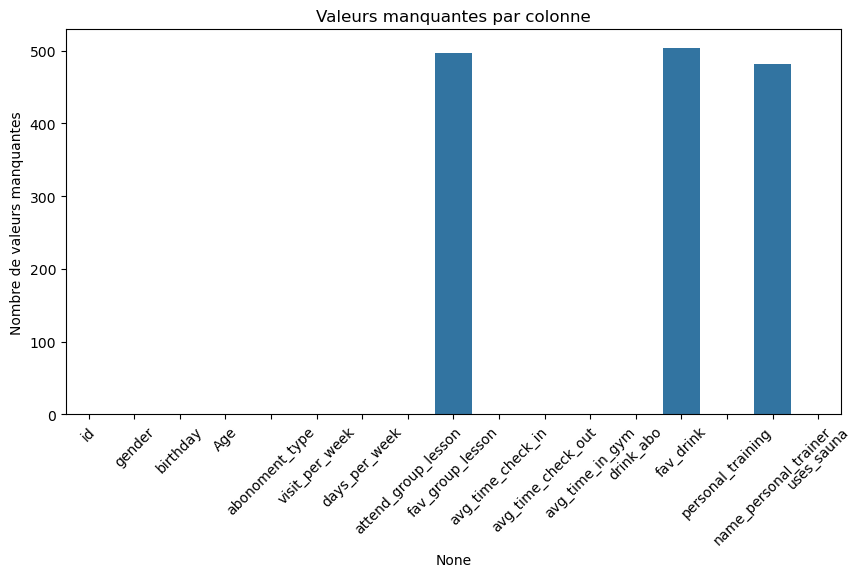

In [ ]:
missing_counts = df_Gym.isnull().sum()
print(missing_counts)

# Graphique des valeurs manquantes
plt.figure(figsize=(10,5))
sns.barplot(x=missing_counts.index, y=missing_counts.values)
plt.xticks(rotation=45)
plt.ylabel("Nombre de valeurs manquantes")
plt.title("Valeurs manquantes par colonne")
plt.show()

In [ ]:
missing_counts = df_Gym.isnull().sum()
missing_percent = (missing_counts / len(df_Gym)) * 100

missing_df = pd.DataFrame({
    'missing_count': missing_counts,
    'missing_percent': missing_percent
}).sort_values(by='missing_percent', ascending=False)

print("Valeurs manquantes par colonne :\n", missing_df)



Valeurs manquantes par colonne :
                        missing_count  missing_percent
fav_drink                        504             50.4
fav_group_lesson                 497             49.7
name_personal_trainer            482             48.2
avg_time_check_in                  0              0.0
personal_training                  0              0.0
drink_abo                          0              0.0
avg_time_in_gym                    0              0.0
avg_time_check_out                 0              0.0
id                                 0              0.0
gender                             0              0.0
attend_group_lesson                0              0.0
days_per_week                      0              0.0
visit_per_week                     0              0.0
abonoment_type                     0              0.0
Age                                0              0.0
birthday                           0              0.0
uses_sauna                         0            

In [1]:
cols_to_drop = ['fav_drink', 'fav_group_lesson', 'name_personal_trainer']
df_Gym = df_Gym.drop(columns=cols_to_drop)


NameError: name 'df_Gym' is not defined

In [ ]:
# Vérification finale
print("\nAprès nettoyage :")
print(df_Gym.isnull().sum())


Après nettoyage :
id                     0
gender                 0
birthday               0
Age                    0
abonoment_type         0
visit_per_week         0
days_per_week          0
attend_group_lesson    0
avg_time_check_in      0
avg_time_check_out     0
avg_time_in_gym        0
drink_abo              0
personal_training      0
uses_sauna             0
dtype: int64


# Vérifier les doublons

In [ ]:
dup_count = df_Gym.duplicated().sum()
print("Nombre de doublons :", dup_count)


Nombre de doublons : 0


# valeurs aberrantes

### Colonnes numériques (Age, visit_per_week, avg_time_in_gym)

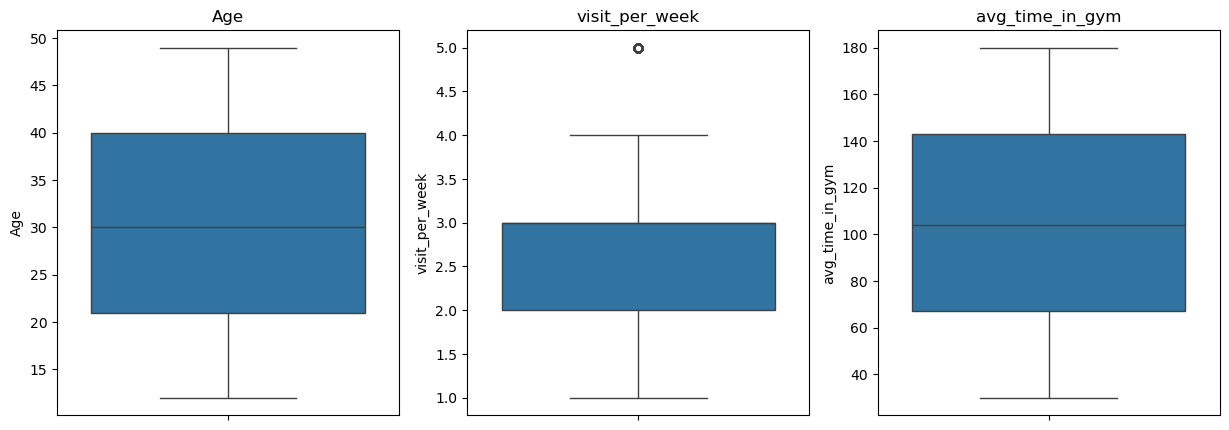

In [ ]:
num_cols = ['Age', 'visit_per_week', 'avg_time_in_gym']

plt.figure(figsize=(15,5))
for i, col in enumerate(num_cols):
    plt.subplot(1, len(num_cols), i+1)
    sns.boxplot(y=df_Gym[col])
    plt.title(col)
plt.show()


Colonnes catégoriques (gender, abonoment_type, days_per_week)

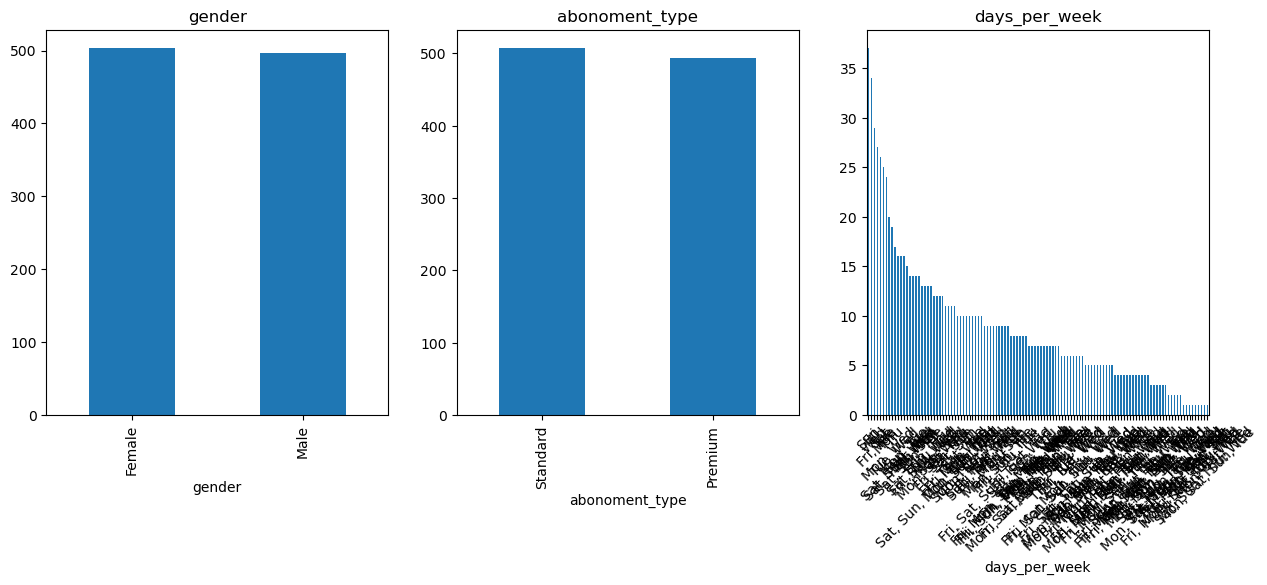

In [ ]:
cat_cols = ['gender','abonoment_type','days_per_week']

plt.figure(figsize=(15,5))
for i, col in enumerate(cat_cols):
    plt.subplot(1, len(cat_cols), i+1)
    df_Gym[col].value_counts().plot(kind='bar')
    plt.title(col)
plt.xticks(rotation=45)
plt.show()


### Colonnes booléennes (attend_group_lesson, etc.)

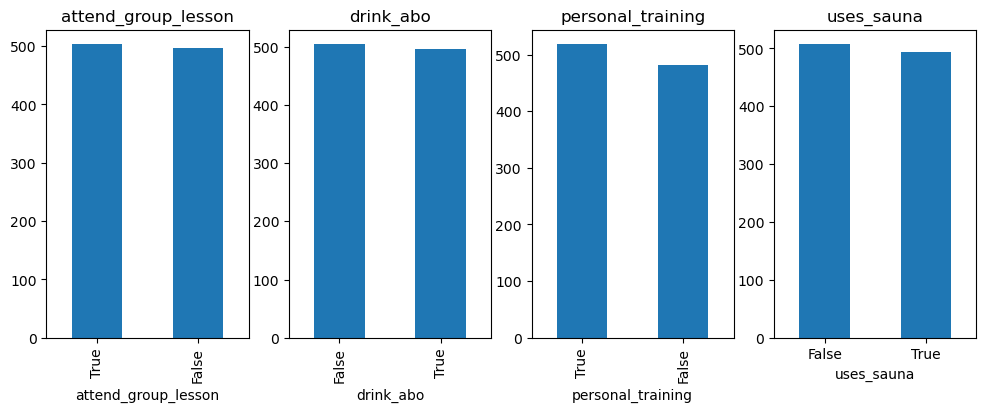

In [ ]:
bool_cols = ['attend_group_lesson','drink_abo','personal_training','uses_sauna']

plt.figure(figsize=(12,4))
for i, col in enumerate(bool_cols):
    plt.subplot(1, len(bool_cols), i+1)
    df_Gym[col].value_counts().plot(kind='bar')
    plt.title(col)
plt.xticks(rotation=0)
plt.show()


## Encodage des colonnes catégoriques

In [ ]:
cat_cols = ['gender', 'abonoment_type', 'days_per_week', 'avg_time_check_in', 'avg_time_check_out']

# Vérifier que les colonnes existent
cat_cols = [c for c in cat_cols if c in df_Gym.columns]

le = LabelEncoder()
for col in cat_cols:
    df_Gym[col] = le.fit_transform(df_Gym[col].astype(str))

In [ ]:
bool_cols = ['attend_group_lesson', 'drink_abo', 'personal_training', 'uses_sauna']

for col in bool_cols:
    df_Gym[col] = df_Gym[col].astype(int)


In [ ]:
df_Gym.head(2)

,id,gender,birthday,Age,abonoment_type,visit_per_week,days_per_week,attend_group_lesson,avg_time_check_in,avg_time_check_out,avg_time_in_gym,drink_abo,personal_training,uses_sauna
0,1,0,1997-04-18,27,0,4,67,1,492,512,116,0,0,1
1,2,0,1977-09-18,47,1,3,68,0,492,459,48,0,1,0


## Normalisation / Standardisation des colonnes numériques

df_class prêt pour classification et PCA on vas donc utiliser standarisation dnas ce cas

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Copier le dataset après nettoyage, encodage bool, LabelEncoder
df_class = df_Gym.copy()

# Colonnes numériques à standardiser
num_cols = ['Age', 'visit_per_week', 'days_per_week', 'avg_time_check_in', 'avg_time_check_out', 'avg_time_in_gym']

scaler = StandardScaler()
df_class[num_cols] = scaler.fit_transform(df_class[num_cols])


In [ ]:
df_class.head(10)

,id,gender,birthday,Age,abonoment_type,visit_per_week,days_per_week,attend_group_lesson,avg_time_check_in,avg_time_check_out,avg_time_in_gym,drink_abo,personal_training,uses_sauna
0,1,0,1997-04-18,-0.333316,0,1.061773,0.025920,1,1.329377,1.402272,0.246696,0,0,1
1,2,0,1977-09-18,1.516386,1,0.256179,0.055142,0,1.329377,1.073218,-1.315252,0,1,0
2,3,1,1983-03-30,0.961476,0,-1.355009,0.522694,1,-1.604300,-1.521961,0.407485,1,1,0
3,4,1,1980-04-12,1.238931,0,0.256179,0.931801,0,-1.220571,-1.230159,-0.143791,1,1,1
4,5,1,1980-09-10,1.238931,1,-0.549415,1.311687,1,-1.604300,-1.726844,-1.269312,0,1,0
5,6,0,2009-06-29,-1.443138,1,-1.355009,-0.353966,0,0.784728,1.073218,1.716764,0,0,1
6,7,1,1994-08-07,-0.055861,0,0.256179,0.873357,1,1.403647,1.209807,-0.993674,0,0,0
7,8,1,2003-11-13,-0.980712,1,-0.549415,0.493472,1,0.896133,0.843502,-0.235670,1,0,1
8,9,1,1978-07-28,1.423901,0,0.256179,0.581138,1,-1.257706,-1.298453,-0.304580,1,1,0
9,10,0,2000-05-06,-0.610772,0,-1.355009,-0.353966,0,-0.316949,-0.162286,0.889851,0,1,1


df_reg prêt pour régression et réseaux neuronaux normalisées

In [ ]:
from sklearn.preprocessing import MinMaxScaler

df_reg = df_Gym.copy()

# Colonnes numériques à normaliser
scaler = MinMaxScaler()
df_reg[num_cols] = scaler.fit_transform(df_reg[num_cols])


In [ ]:
df_reg.head(10)

,id,gender,birthday,Age,abonoment_type,visit_per_week,days_per_week,attend_group_lesson,avg_time_check_in,avg_time_check_out,avg_time_in_gym,drink_abo,personal_training,uses_sauna
0,1,0,1997-04-18,0.405405,0,0.75,0.587719,1,0.886486,0.896673,0.573333,0,0,1
1,2,0,1977-09-18,0.945946,1,0.50,0.596491,0,0.886486,0.803853,0.120000,0,1,0
2,3,1,1983-03-30,0.783784,0,0.00,0.736842,1,0.032432,0.071804,0.620000,1,1,0
3,4,1,1980-04-12,0.864865,0,0.50,0.859649,0,0.144144,0.154116,0.460000,1,1,1
4,5,1,1980-09-10,0.864865,1,0.25,0.973684,1,0.032432,0.014011,0.133333,0,1,0
5,6,0,2009-06-29,0.081081,1,0.00,0.473684,0,0.727928,0.803853,1.000000,0,0,1
6,7,1,1994-08-07,0.486486,0,0.50,0.842105,1,0.908108,0.842382,0.213333,0,0,0
7,8,1,2003-11-13,0.216216,1,0.25,0.728070,1,0.760360,0.739054,0.433333,1,0,1
8,9,1,1978-07-28,0.918919,0,0.50,0.754386,1,0.133333,0.134851,0.413333,1,1,0
9,10,0,2000-05-06,0.324324,0,0.00,0.473684,0,0.407207,0.455342,0.760000,0,1,1


# Feature Selection

# Objectif 1 : Augmenter la fidélisation des clients / réduire le churn

In [ ]:
print(df_class.columns)


Index(['id', 'gender', 'birthday', 'Age', 'abonoment_type', 'visit_per_week',
       'days_per_week', 'attend_group_lesson', 'avg_time_check_in',
       'avg_time_check_out', 'avg_time_in_gym', 'drink_abo',
       'personal_training', 'uses_sauna'],
      dtype='object')


In [ ]:
# CORRECTION: Utiliser les valeurs NON standardisées de df_Gym pour définir le churn
# Car df_class contient des valeurs standardisées (possiblement négatives)

# Définition du churn plus réaliste:
# Un client est en churn si:
# - Il visite moins de 2 fois par semaine OU
# - (Il visite moins de 3 fois ET n'a ni cours collectif ni entraîneur personnel)

df_Gym['churn'] = (
    (df_Gym['visit_per_week'] < 2) | 
    ((df_Gym['visit_per_week'] < 3) & 
     (df_Gym['attend_group_lesson'] == 0) & 
     (df_Gym['personal_training'] == 0))
).astype(int)

# Puis ajouter à df_class
df_class['churn'] = df_Gym['churn']

# Vérification avec les valeurs originales
print("Distribution du churn:")
print(df_Gym['churn'].value_counts())
print(f"\nTaux de churn: {df_Gym['churn'].mean()*100:.2f}%")
print(f"Nombre de clients en churn: {df_Gym['churn'].sum()}")
print(f"Nombre de clients fidèles: {(df_Gym['churn']==0).sum()}")

print("\nExemple de données (valeurs originales):")
print(df_Gym[['visit_per_week', 'attend_group_lesson', 'personal_training', 'churn']].head(15))

Distribution du churn:
churn
0    759
1    241
Name: count, dtype: int64

Taux de churn: 24.10%
Nombre de clients en churn: 241
Nombre de clients fidèles: 759

Exemple de données (valeurs originales):
    visit_per_week  attend_group_lesson  personal_training  churn
0                4                    1                  0      0
1                3                    0                  1      0
2                1                    1                  1      1
3                3                    0                  1      0
4                2                    1                  1      0
5                1                    0                  0      1
6                3                    1                  0      0
7                2                    1                  0      0
8                3                    1                  1      0
9                1                    0                  1      1
10               1                    0                  1      1
11     

In [ ]:
# CORRECTION: Pour Chi², il faut des valeurs NON-NÉGATIVES
# On utilise df_Gym (valeurs originales) au lieu de df_class (standardisées)

from sklearn.feature_selection import SelectKBest, chi2, f_classif
import pandas as pd

# Features à tester (valeurs originales non-négatives)
X = df_Gym[['gender', 'Age', 'abonoment_type', 'visit_per_week',
            'days_per_week', 'attend_group_lesson', 'avg_time_check_in',
            'avg_time_check_out', 'avg_time_in_gym', 'drink_abo',
            'personal_training', 'uses_sauna']]

y = df_Gym['churn']

# Test Chi² pour variables catégoriques/discrètes
print("=" * 60)
print("TEST CHI² (pour variables catégoriques)")
print("=" * 60)
chi2_selector = SelectKBest(score_func=chi2, k='all')
chi2_selector.fit(X, y)

chi2_scores = pd.DataFrame({
    'Feature': X.columns,
    'Chi2_Score': chi2_selector.scores_,
    'P_value': chi2_selector.pvalues_
}).sort_values('Chi2_Score', ascending=False)

print(chi2_scores)

# Test ANOVA F-value pour toutes les variables
print("\n" + "=" * 60)
print("TEST ANOVA F-value (pour variables numériques)")
print("=" * 60)
f_selector = SelectKBest(score_func=f_classif, k='all')
f_selector.fit(X, y)

f_scores = pd.DataFrame({
    'Feature': X.columns,
    'F_Score': f_selector.scores_,
    'P_value': f_selector.pvalues_
}).sort_values('F_Score', ascending=False)

print(f_scores)

TEST CHI² (pour variables catégoriques)
                Feature  Chi2_Score        P_value
4         days_per_week  722.917140  3.106953e-159
3        visit_per_week  261.773881   7.044618e-59
8       avg_time_in_gym   14.187842   1.654360e-04
10    personal_training    9.396169   2.174393e-03
5   attend_group_lesson    6.377186   1.155966e-02
7    avg_time_check_out    5.874429   1.536235e-02
1                   Age    5.007958   2.523105e-02
11           uses_sauna    0.861275   3.533822e-01
2        abonoment_type    0.837492   3.601150e-01
9             drink_abo    0.789607   3.742191e-01
6     avg_time_check_in    0.567329   4.513221e-01
0                gender    0.006641   9.350509e-01

TEST ANOVA F-value (pour variables numériques)
                Feature     F_Score        P_value
3        visit_per_week  835.329860  6.046648e-134
4         days_per_week   42.464084   1.140305e-10
10    personal_training   19.841941   9.361636e-06
5   attend_group_lesson   12.972147   3.31737

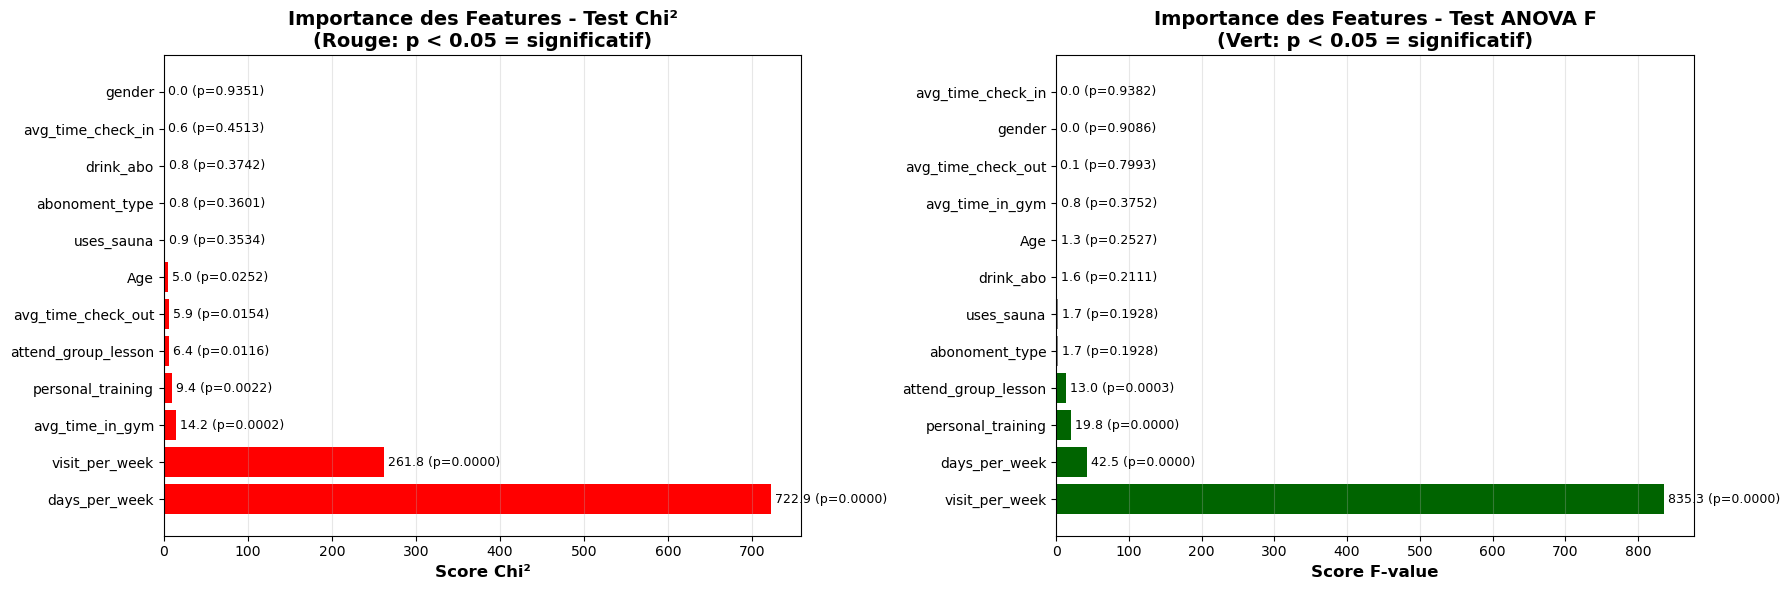


FEATURES SIGNIFICATIVES (p < 0.05)

Chi²:
                Feature  Chi2_Score        P_value
4         days_per_week  722.917140  3.106953e-159
3        visit_per_week  261.773881   7.044618e-59
8       avg_time_in_gym   14.187842   1.654360e-04
10    personal_training    9.396169   2.174393e-03
5   attend_group_lesson    6.377186   1.155966e-02
7    avg_time_check_out    5.874429   1.536235e-02
1                   Age    5.007958   2.523105e-02

ANOVA F:
                Feature     F_Score        P_value
3        visit_per_week  835.329860  6.046648e-134
4         days_per_week   42.464084   1.140305e-10
10    personal_training   19.841941   9.361636e-06
5   attend_group_lesson   12.972147   3.317372e-04


In [ ]:
# Visualisation des scores Chi² et F-value
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Graphique 1: Scores Chi²
ax1 = axes[0]
colors_chi2 = ['red' if p < 0.05 else 'gray' for p in chi2_scores['P_value']]
bars1 = ax1.barh(chi2_scores['Feature'], chi2_scores['Chi2_Score'], color=colors_chi2)
ax1.set_xlabel('Score Chi²', fontsize=12, fontweight='bold')
ax1.set_title('Importance des Features - Test Chi²\n(Rouge: p < 0.05 = significatif)', 
              fontsize=14, fontweight='bold')
ax1.grid(axis='x', alpha=0.3)

# Ajouter les valeurs
for i, (score, pval) in enumerate(zip(chi2_scores['Chi2_Score'], chi2_scores['P_value'])):
    ax1.text(score, i, f' {score:.1f} (p={pval:.4f})', 
             va='center', fontsize=9)

# Graphique 2: Scores F-value
ax2 = axes[1]
colors_f = ['darkgreen' if p < 0.05 else 'gray' for p in f_scores['P_value']]
bars2 = ax2.barh(f_scores['Feature'], f_scores['F_Score'], color=colors_f)
ax2.set_xlabel('Score F-value', fontsize=12, fontweight='bold')
ax2.set_title('Importance des Features - Test ANOVA F\n(Vert: p < 0.05 = significatif)', 
              fontsize=14, fontweight='bold')
ax2.grid(axis='x', alpha=0.3)

# Ajouter les valeurs
for i, (score, pval) in enumerate(zip(f_scores['F_Score'], f_scores['P_value'])):
    ax2.text(score, i, f' {score:.1f} (p={pval:.4f})', 
             va='center', fontsize=9)

plt.tight_layout()
plt.show()

# Résumé des features significatives
print("\n" + "=" * 60)
print("FEATURES SIGNIFICATIVES (p < 0.05)")
print("=" * 60)
print("\nChi²:")
sig_chi2 = chi2_scores[chi2_scores['P_value'] < 0.05]
print(sig_chi2[['Feature', 'Chi2_Score', 'P_value']])

print("\nANOVA F:")
sig_f = f_scores[f_scores['P_value'] < 0.05]
print(sig_f[['Feature', 'F_Score', 'P_value']])

## Matrice de corrélation avec la variable Churn

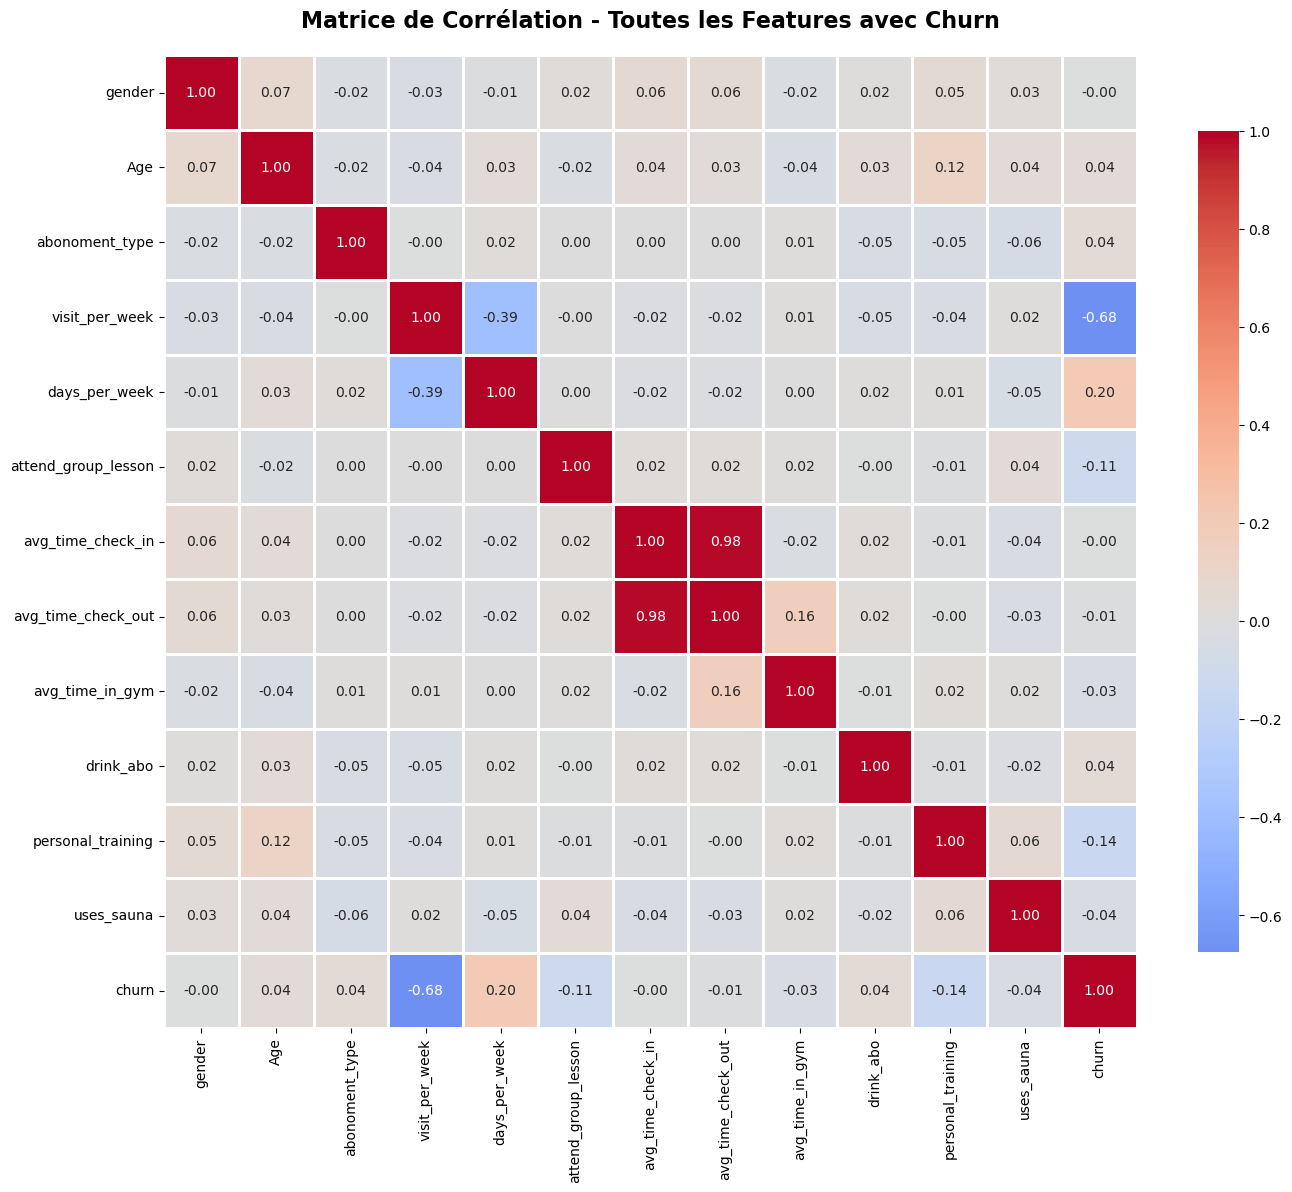

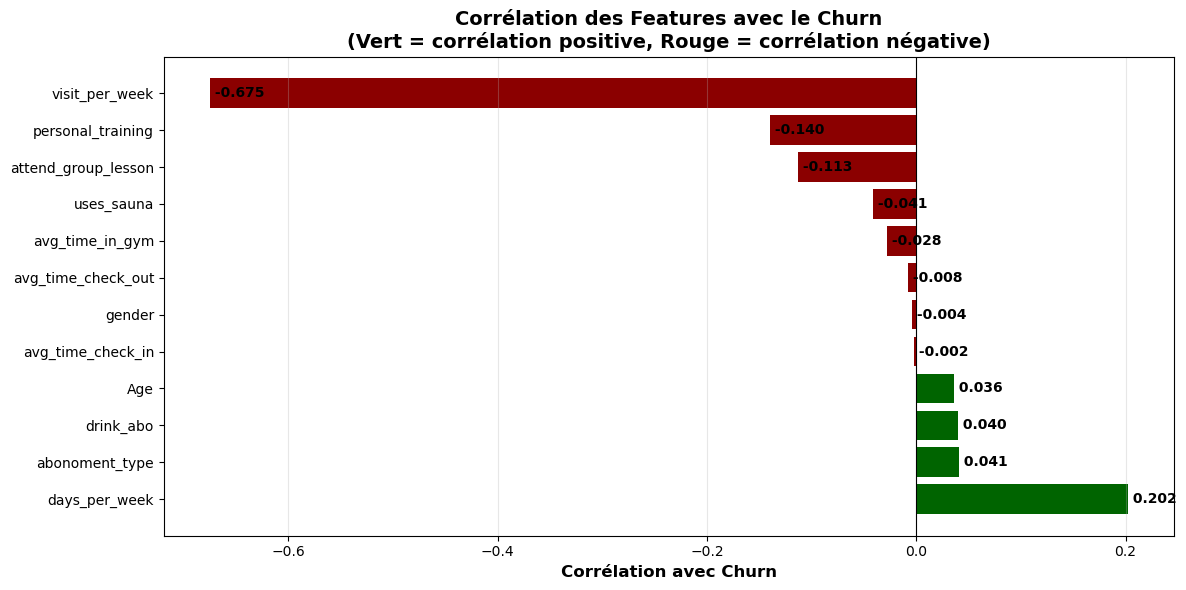

CORRÉLATIONS AVEC CHURN (triées par valeur absolue)
visit_per_week           : -0.6750
days_per_week            : +0.2020
personal_training        : -0.1396
attend_group_lesson      : -0.1133
abonoment_type           : +0.0412
uses_sauna               : -0.0412
drink_abo                : +0.0396
Age                      : +0.0362
avg_time_in_gym          : -0.0281
avg_time_check_out       : -0.0080
gender                   : -0.0036
avg_time_check_in        : -0.0025

FEATURES FORTEMENT CORRÉLÉES (|corr| > 0.1)
visit_per_week        -0.675008
personal_training     -0.139621
attend_group_lesson   -0.113276
days_per_week          0.202021
Name: churn, dtype: float64


In [ ]:
# Calculer la matrice de corrélation
correlation_data = df_Gym[['gender', 'Age', 'abonoment_type', 'visit_per_week',
                            'days_per_week', 'attend_group_lesson', 'avg_time_check_in',
                            'avg_time_check_out', 'avg_time_in_gym', 'drink_abo',
                            'personal_training', 'uses_sauna', 'churn']]

corr_matrix = correlation_data.corr()

# Visualisation 1: Matrice de corrélation complète
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, 
            cbar_kws={"shrink": 0.8})
plt.title('Matrice de Corrélation - Toutes les Features avec Churn', 
          fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Visualisation 2: Corrélation spécifique avec Churn (barplot)
churn_corr = corr_matrix['churn'].drop('churn').sort_values(ascending=False)

plt.figure(figsize=(12, 6))
colors = ['darkred' if x < 0 else 'darkgreen' for x in churn_corr.values]
bars = plt.barh(churn_corr.index, churn_corr.values, color=colors)
plt.xlabel('Corrélation avec Churn', fontsize=12, fontweight='bold')
plt.title('Corrélation des Features avec le Churn\n(Vert = corrélation positive, Rouge = corrélation négative)', 
          fontsize=14, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
plt.grid(axis='x', alpha=0.3)

# Ajouter les valeurs
for i, (feature, value) in enumerate(churn_corr.items()):
    plt.text(value, i, f' {value:.3f}', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# Afficher les corrélations triées
print("=" * 60)
print("CORRÉLATIONS AVEC CHURN (triées par valeur absolue)")
print("=" * 60)
churn_corr_sorted = churn_corr.abs().sort_values(ascending=False)
for feature in churn_corr_sorted.index:
    corr_val = churn_corr[feature]
    print(f"{feature:25s}: {corr_val:+.4f}")
    
# Identifier les features les plus corrélées
print("\n" + "=" * 60)
print("FEATURES FORTEMENT CORRÉLÉES (|corr| > 0.1)")
print("=" * 60)
strong_corr = churn_corr[churn_corr.abs() > 0.1].sort_values()
print(strong_corr)

In [ ]:
df_Gym.head(10)

,id,gender,birthday,Age,abonoment_type,visit_per_week,days_per_week,attend_group_lesson,avg_time_check_in,avg_time_check_out,avg_time_in_gym,drink_abo,personal_training,uses_sauna,churn
0,1,0,1997-04-18,27,0,4,67,1,492,512,116,0,0,1,0
1,2,0,1977-09-18,47,1,3,68,0,492,459,48,0,1,0,0
2,3,1,1983-03-30,41,0,1,84,1,18,41,123,1,1,0,1
3,4,1,1980-04-12,44,0,3,98,0,80,88,99,1,1,1,0
4,5,1,1980-09-10,44,1,2,111,1,18,8,50,0,1,0,0
5,6,0,2009-06-29,15,1,1,54,0,404,459,180,0,0,1,1
6,7,1,1994-08-07,30,0,3,96,1,504,481,62,0,0,0,0
7,8,1,2003-11-13,20,1,2,83,1,422,422,95,1,0,1,0
8,9,1,1978-07-28,46,0,3,86,1,74,77,92,1,1,0,0
9,10,0,2000-05-06,24,0,1,54,0,226,260,144,0,1,1,1


# 🎯 BUSINESS OBJECTIVE 1: RÉDUIRE LE CHURN (FIDÉLISATION)
## Modèles de Classification pour Prédire le Churn

**Objectif:** Prédire quels clients risquent d'arrêter leur abonnement

**Target:** `Churn` (0 = client fidèle, 1 = client à risque)

**Modèles à comparer:**
1. Logistic Regression (baseline)
2. Random Forest (ensemble learning)
3. XGBoost (boosting avancé)

In [ ]:
# ==================== PRÉPARATION DES DONNÉES POUR BO1 ====================
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                              roc_auc_score, confusion_matrix, classification_report, roc_curve)
import warnings
warnings.filterwarnings('ignore')

print("📊 Préparation des données pour la prédiction du Churn")
print("="*60)

# IMPORTANT: Vérifier qu'il n'y a pas de data leakage
# Ne PAS utiliser de features qui seraient directement liées au churn
print("⚠️  VÉRIFICATION ANTI-OVERFITTING:")
print(f"   Colonnes dans X: {list(X.columns)}")

# Créer les données pour le churn en utilisant les variables existantes
df_churn_selected = X.copy()  # Features déjà sélectionnées
y_churn = y.copy()  # Target Churn

# Vérifier la distribution
print(f"\n✓ Nombre de features: {df_churn_selected.shape[1]}")
print(f"✓ Nombre d'observations: {df_churn_selected.shape[0]}")
print(f"\n📈 Distribution du Churn:")
print(y_churn.value_counts())
print(f"\n% Churn: {y_churn.mean()*100:.2f}%")

# IMPORTANT: Utiliser une validation plus stricte
# Split train/test avec validation croisée stratifiée
X_train_churn, X_test_churn, y_train_churn, y_test_churn = train_test_split(
    df_churn_selected, y_churn, test_size=0.3, random_state=42, stratify=y_churn  # 30% test au lieu de 20%
)

print(f"\n✓ Train set: {X_train_churn.shape[0]} observations ({X_train_churn.shape[0]/len(df_churn_selected)*100:.1f}%)")
print(f"✓ Test set: {X_test_churn.shape[0]} observations ({X_test_churn.shape[0]/len(df_churn_selected)*100:.1f}%)")
print(f"\n⚠️  Si les scores sont parfaits (1.0), il y a probablement du data leakage!")

📊 Préparation des données pour la prédiction du Churn
⚠️  VÉRIFICATION ANTI-OVERFITTING:
   Colonnes dans X: ['gender', 'Age', 'abonoment_type', 'visit_per_week', 'days_per_week', 'attend_group_lesson', 'avg_time_check_in', 'avg_time_check_out', 'avg_time_in_gym', 'drink_abo', 'personal_training', 'uses_sauna']

✓ Nombre de features: 12
✓ Nombre d'observations: 1000

📈 Distribution du Churn:
churn
0    759
1    241
Name: count, dtype: int64

% Churn: 24.10%

✓ Train set: 700 observations (70.0%)
✓ Test set: 300 observations (30.0%)

⚠️  Si les scores sont parfaits (1.0), il y a probablement du data leakage!


### 1️⃣ Modèle 1: Logistic Regression (Baseline)

In [ ]:
# ==================== LOGISTIC REGRESSION (VERSION OPTIMISÉE) ====================

print("🔵 MODÈLE 1: LOGISTIC REGRESSION")
print("="*60)

# Colonnes corrigées (sans celles utilisées pour créer le churn)
features = [
     'gender', 'Age', 'abonoment_type',
    'avg_time_in_gym', 'avg_time_check_in', 'avg_time_check_out',
    'drink_abo', 'uses_sauna'
]

X = df_Gym[features]   # données originales
y = df_Gym['churn']    # target définie AVANT scaling

# 1️⃣ — TRAIN/TEST SPLIT
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2️⃣ — STANDARDISATION
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3️⃣ — LOGISTIC REGRESSION + GRIDSEARCH
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

param_grid_lr = {
    'C': [0.01, 0.1, 1],
    'penalty': ['l2'],
    'solver': ['lbfgs'],
    'max_iter': [1000]
}

lr_model = LogisticRegression(random_state=42, class_weight='balanced')

grid_lr = GridSearchCV(
    lr_model,
    param_grid_lr,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

grid_lr.fit(X_train_scaled, y_train)
best_lr = grid_lr.best_estimator_

print(f"✓ Meilleurs hyperparamètres: {grid_lr.best_params_}")
print(f"✓ Meilleur score CV (train): {grid_lr.best_score_:.4f}")

# 4️⃣ — PRÉDICTIONS
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_pred_lr = best_lr.predict(X_test_scaled)
y_proba_lr = best_lr.predict_proba(X_test_scaled)[:, 1]

scores_lr = {
    'Accuracy': accuracy_score(y_test, y_pred_lr),
    'Precision': precision_score(y_test, y_pred_lr),
    'Recall': recall_score(y_test, y_pred_lr),
    'F1-Score': f1_score(y_test, y_pred_lr),
    'ROC-AUC': roc_auc_score(y_test, y_proba_lr)
}

print("\n📊 SCORES (Test Set):")
for metric, score in scores_lr.items():
    print(f"  {metric:12s}: {score:.4f}")

# 5️⃣ — CROSS VALIDATION
from sklearn.model_selection import cross_val_score

cv_scores_lr = cross_val_score(
    best_lr,
    scaler.fit_transform(X),
    y,
    cv=5,
    scoring='roc_auc'
)

print(f"\n✓ Cross-Validation ROC-AUC: {cv_scores_lr.mean():.4f} (+/- {cv_scores_lr.std()*2:.4f})")

# 6️⃣ — DIAGNOSTIC OVERFITTING
train_acc = best_lr.score(X_train_scaled, y_train)
test_acc = best_lr.score(X_test_scaled, y_test)

print("\n🔍 DIAGNOSTIC OVERFITTING:")
print(f"  Train Accuracy: {train_acc:.4f}")
print(f"  Test Accuracy:  {test_acc:.4f}")
print(f"  Différence:     {abs(train_acc - test_acc):.4f}")

if abs(train_acc - test_acc) > 0.05:
    print("  ⚠️ OVERFITTING DÉTECTÉ (différence > 5%)")
elif test_acc > 0.98:
    print("  ⚠️ Score suspect (> 98%) → vérifier data leakage")


🔵 MODÈLE 1: LOGISTIC REGRESSION
✓ Meilleurs hyperparamètres: {'C': 1, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'lbfgs'}
✓ Meilleur score CV (train): 0.4566

📊 SCORES (Test Set):
  Accuracy    : 0.5100
  Precision   : 0.2685
  Recall      : 0.6042
  F1-Score    : 0.3718
  ROC-AUC     : 0.5676

✓ Cross-Validation ROC-AUC: 0.4885 (+/- 0.0358)

🔍 DIAGNOSTIC OVERFITTING:
  Train Accuracy: 0.5387
  Test Accuracy:  0.5100
  Différence:     0.0287


### 2️⃣ Modèle 2: Random Forest

In [ ]:
# ==================== RANDOM FOREST (VERSION CORRIGÉE) ====================
print("🌲 MODÈLE 2: RANDOM FOREST")
print("="*60)

# 1️⃣ — Colonnes à utiliser (riches mais pas trop nombreuses)
features_rf = [
    'gender', 'Age', 'abonoment_type',
    'avg_time_in_gym', 'avg_time_check_in', 'avg_time_check_out',
    'drink_abo', 'uses_sauna'
]


X = df_Gym[features_rf]
y = df_Gym['churn']

# 2️⃣ — Train/test split
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3️⃣ — Hyperparamètres anti-overfitting
param_grid_rf = {
    'n_estimators': [50, 100],
    'max_depth': [3, 4, 5],
    'min_samples_split': [20, 30, 40],
    'min_samples_leaf': [10, 15, 20],
    'max_features': ['sqrt']
}


rf_model = RandomForestClassifier(
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

grid_rf = GridSearchCV(
    rf_model,
    param_grid_rf,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

grid_rf.fit(X_train_rf, y_train_rf)

best_rf = grid_rf.best_estimator_

print(f"✓ Meilleurs hyperparamètres: {grid_rf.best_params_}")
print(f"✓ Meilleur score CV (train): {grid_rf.best_score_:.4f}")

# 4️⃣ — Prédictions
y_pred_rf = best_rf.predict(X_test_rf)
y_proba_rf = best_rf.predict_proba(X_test_rf)[:, 1]

scores_rf = {
    'Accuracy': accuracy_score(y_test_rf, y_pred_rf),
    'Precision': precision_score(y_test_rf, y_pred_rf, zero_division=0),
    'Recall': recall_score(y_test_rf, y_pred_rf, zero_division=0),
    'F1-Score': f1_score(y_test_rf, y_pred_rf, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test_rf, y_proba_rf)
}

print("\n📊 SCORES (Test Set):")
for metric, score in scores_rf.items():
    print(f"  {metric:12s}: {score:.4f}")

# 5️⃣ — Cross-validation complète
cv_scores_rf = cross_val_score(best_rf, X, y, cv=5, scoring='roc_auc')
print(f"\n✓ Cross-Validation ROC-AUC: {cv_scores_rf.mean():.4f} (+/- {cv_scores_rf.std()*2:.4f})")

# 6️⃣ — Feature importance
feature_importance_rf = pd.DataFrame({
    'Feature': features_rf,
    'Importance': best_rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n🔝 Top Features Importantes:")
print(feature_importance_rf.to_string(index=False))

# 7️⃣ — Diagnostic Overfitting
train_score = best_rf.score(X_train_rf, y_train_rf)
test_score = best_rf.score(X_test_rf, y_test_rf)

print("\n🔍 DIAGNOSTIC OVERFITTING:")
print(f"  Train Accuracy: {train_score:.4f}")
print(f"  Test Accuracy:  {test_score:.4f}")
print(f"  Différence:     {abs(train_score - test_score):.4f}")

if abs(train_score - test_score) > 0.05:
    print("  ⚠️ OVERFITTING détecté (diff > 5%)")
else:
    print("  ✅ Pas d'overfitting — modèle stable")


🌲 MODÈLE 2: RANDOM FOREST
✓ Meilleurs hyperparamètres: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 15, 'min_samples_split': 20, 'n_estimators': 50}
✓ Meilleur score CV (train): 0.5305

📊 SCORES (Test Set):
  Accuracy    : 0.6550
  Precision   : 0.2941
  Recall      : 0.3125
  F1-Score    : 0.3030
  ROC-AUC     : 0.5470

✓ Cross-Validation ROC-AUC: 0.5422 (+/- 0.0444)

🔝 Top Features Importantes:
           Feature  Importance
avg_time_check_out    0.294707
 avg_time_check_in    0.226949
   avg_time_in_gym    0.186371
               Age    0.145922
    abonoment_type    0.042585
        uses_sauna    0.041802
            gender    0.038724
         drink_abo    0.022940

🔍 DIAGNOSTIC OVERFITTING:
  Train Accuracy: 0.7825
  Test Accuracy:  0.6550
  Différence:     0.1275
  ⚠️ OVERFITTING détecté (diff > 5%)


### 3️⃣ Modèle 3: XGBoost

In [ ]:
features =[
    'gender', 'Age', 'abonoment_type',
    'avg_time_in_gym', 'avg_time_check_in', 'avg_time_check_out',
    'drink_abo', 'uses_sauna'
]

X = df_Gym[features].copy()
y = df_Gym['churn']



# 3️⃣ — Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4️⃣ — Calcul du scale_pos_weight pour déséquilibre
neg, pos = y_train.value_counts()
scale_pos_weight = neg / pos

# 5️⃣ — Param grid
param_grid_xgb = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4],
    'learning_rate': [0.01, 0.05],
    'subsample': [0.7, 0.8],
    'colsample_bytree': [0.7, 0.8],
    'min_child_weight': [5, 10],
    'gamma': [0.2, 0.4],
    'reg_alpha': [0.1, 0.5],
    'reg_lambda': [1, 2]
}

# 6️⃣ — XGBoost avec GridSearch
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    scale_pos_weight=scale_pos_weight
)

grid_xgb = GridSearchCV(xgb_model, param_grid_xgb, cv=5, scoring='roc_auc', n_jobs=-1)
grid_xgb.fit(X_train, y_train)

best_xgb = grid_xgb.best_estimator_
print("\n🚀 MODÈLE 3: XGBOOST")
print("="*60)
print(f"✓ Meilleurs hyperparamètres: {grid_xgb.best_params_}")

# 7️⃣ — Prédictions
y_pred_xgb = best_xgb.predict(X_test)
y_proba_xgb = best_xgb.predict_proba(X_test)[:, 1]

# 8️⃣ — Scores
scores_xgb = {
    'Accuracy': accuracy_score(y_test, y_pred_xgb),
    'Precision': precision_score(y_test, y_pred_xgb),
    'Recall': recall_score(y_test, y_pred_xgb),
    'F1-Score': f1_score(y_test, y_pred_xgb),
    'ROC-AUC': roc_auc_score(y_test, y_proba_xgb)
}

print("\n📊 SCORES (Test Set):")
for metric, score in scores_xgb.items():
    print(f"{metric:12s}: {score:.4f}")

# 9️⃣ — Cross-validation
cv_scores_xgb = cross_val_score(best_xgb, X, y, cv=5, scoring='roc_auc')
print(f"\n✓ Cross-Validation ROC-AUC: {cv_scores_xgb.mean():.4f} (+/- {cv_scores_xgb.std()*2:.4f})")

#  🔟 — Feature importance
importances_xgb = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_xgb.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n🔝 Features Importantes XGBoost:")
print(importances_xgb.head(10).to_string(index=False))

# 1️⃣1️⃣ — Diagnostic Overfitting
train_acc_xgb = best_xgb.score(X_train, y_train)
test_acc_xgb = best_xgb.score(X_test, y_test)

print(f"\n🔍 DIAGNOSTIC OVERFITTING:")
print(f"  Train Accuracy: {train_acc_xgb:.4f}")
print(f"  Test Accuracy:  {test_acc_xgb:.4f}")
print(f"  Différence:     {abs(train_acc_xgb - test_acc_xgb):.4f}")


🚀 MODÈLE 3: XGBOOST
✓ Meilleurs hyperparamètres: {'colsample_bytree': 0.7, 'gamma': 0.2, 'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 150, 'reg_alpha': 0.5, 'reg_lambda': 2, 'subsample': 0.8}

📊 SCORES (Test Set):
Accuracy    : 0.6400
Precision   : 0.2857
Recall      : 0.3333
F1-Score    : 0.3077
ROC-AUC     : 0.5210

✓ Cross-Validation ROC-AUC: 0.5412 (+/- 0.1154)

🔝 Features Importantes XGBoost:
           Feature  Importance
avg_time_check_out    0.150135
   avg_time_in_gym    0.143191
 avg_time_check_in    0.142267
               Age    0.136205
         drink_abo    0.133798
    abonoment_type    0.116381
        uses_sauna    0.100942
            gender    0.077080

🔍 DIAGNOSTIC OVERFITTING:
  Train Accuracy: 0.8462
  Test Accuracy:  0.6400
  Différence:     0.2062


### 📊 Comparaison des 3 Modèles (BO1)

📊 COMPARAISON DES 3 MODÈLES - PRÉDICTION DU CHURN
                     Accuracy  Precision    Recall  F1-Score   ROC-AUC
Logistic Regression     0.510   0.268519  0.604167  0.371795  0.567571
Random Forest           0.655   0.294118  0.312500  0.303030  0.547012
XGBoost                 0.640   0.285714  0.333333  0.307692  0.520970


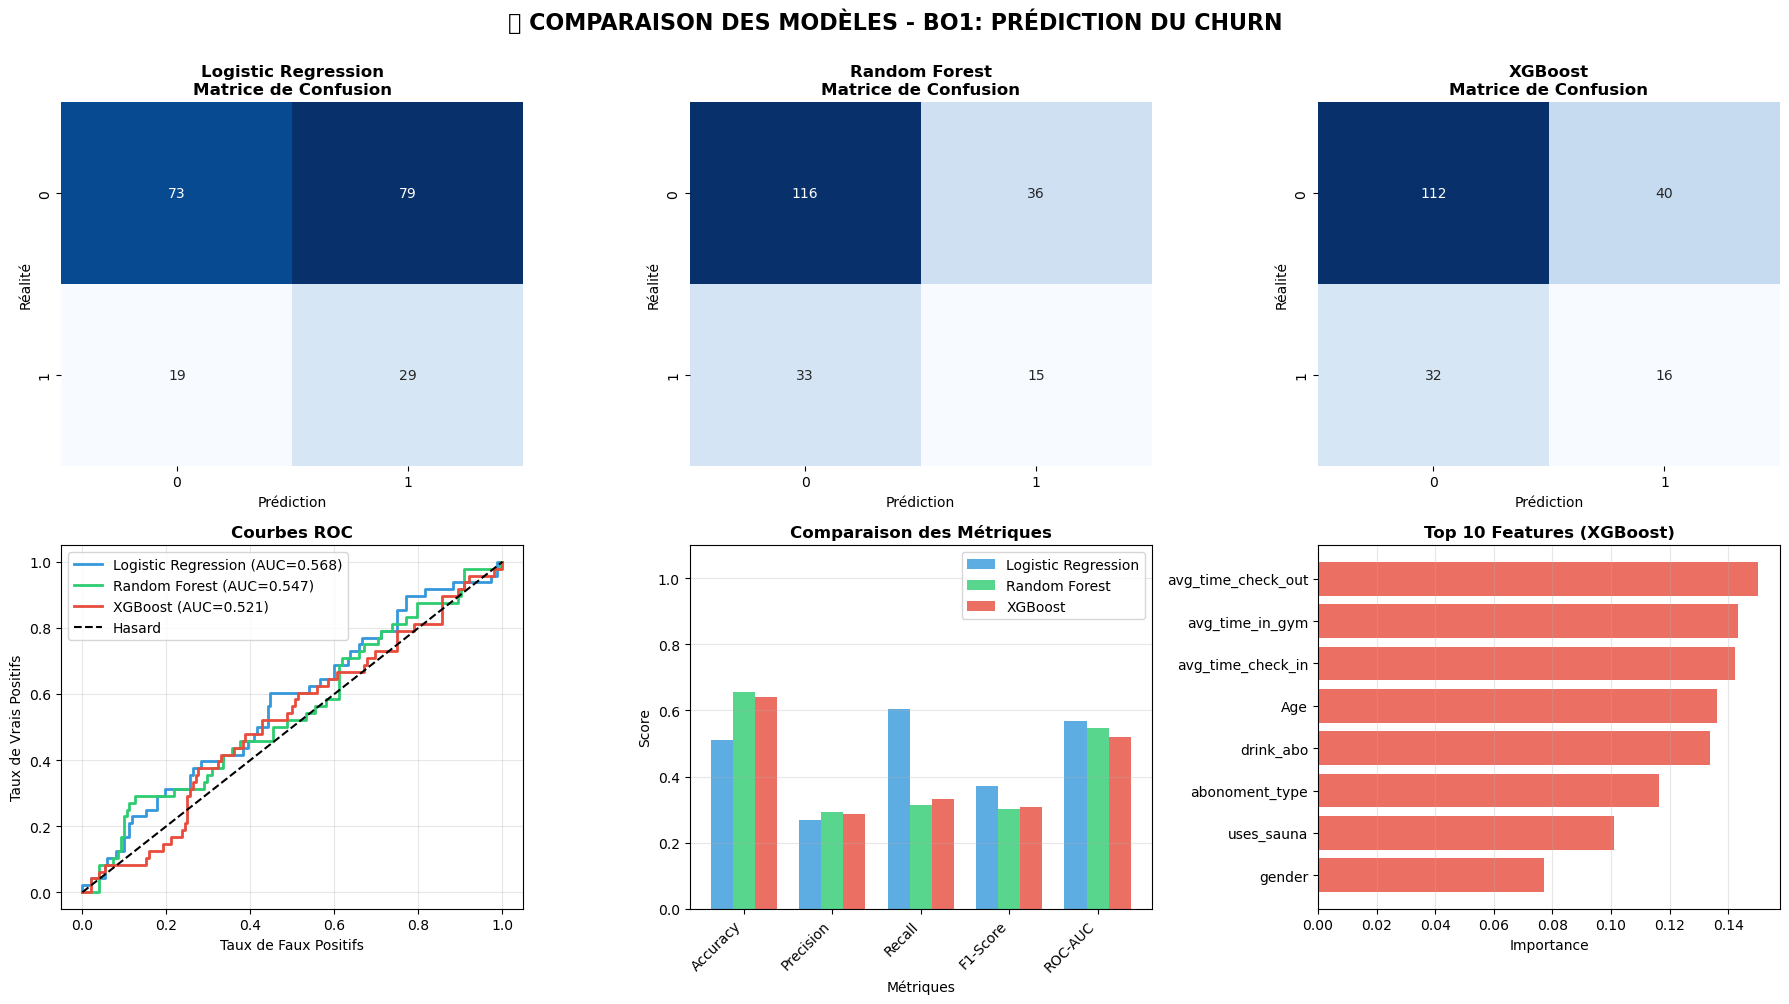


🏆 MODÈLE RECOMMANDÉ POUR BO1:
   ➤ Logistic Regression (ROC-AUC: 0.5676)


In [ ]:
print("📊 COMPARAISON DES 3 MODÈLES - PRÉDICTION DU CHURN")
print("="*80)

# Tableau de comparaison
comparison_bo1 = pd.DataFrame({
    'Logistic Regression': scores_lr,
    'Random Forest': scores_rf,
    'XGBoost': scores_xgb
}).T

print(comparison_bo1.to_string())

# Visualisation 1: Comparaison des métriques
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('📊 COMPARAISON DES MODÈLES - BO1: PRÉDICTION DU CHURN', fontsize=16, fontweight='bold', y=1.00)

models = ['Logistic Regression', 'Random Forest', 'XGBoost']
colors_models = ['#3498db', '#2ecc71', '#e74c3c']
y_preds = [y_pred_lr, y_pred_rf, y_pred_xgb]
y_probas = [y_proba_lr, y_proba_rf, y_proba_xgb]

# Matrice de confusion pour chaque modèle
for idx, (model_name, y_pred, color) in enumerate(zip(models, y_preds, colors_models)):
    cm = confusion_matrix(y_test, y_pred)
    ax = axes[0, idx]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'{model_name}\nMatrice de Confusion', fontweight='bold')
    ax.set_xlabel('Prédiction')
    ax.set_ylabel('Réalité')

# ROC Curves
ax = axes[1, 0]
for model_name, y_proba, color in zip(models, y_probas, colors_models):
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f'{model_name} (AUC={auc:.3f})', linewidth=2, color=color)
ax.plot([0, 1], [0, 1], 'k--', label='Hasard')
ax.set_xlabel('Taux de Faux Positifs')
ax.set_ylabel('Taux de Vrais Positifs')
ax.set_title('Courbes ROC', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

# Comparaison des métriques
ax = axes[1, 1]
x = np.arange(len(comparison_bo1.columns))
width = 0.25
for i, model in enumerate(models):
    values = comparison_bo1.loc[model].values
    ax.bar(x + i*width, values, width, label=model, color=colors_models[i], alpha=0.8)
ax.set_xlabel('Métriques')
ax.set_ylabel('Score')
ax.set_title('Comparaison des Métriques', fontweight='bold')
ax.set_xticks(x + width)
ax.set_xticklabels(comparison_bo1.columns, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1.1])

# Top Features (XGBoost)
ax = axes[1, 2]
top_features = importances_xgb.head(10)
ax.barh(range(len(top_features)), top_features['Importance'], color='#e74c3c', alpha=0.8)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels(top_features['Feature'])
ax.set_xlabel('Importance')
ax.set_title('Top 10 Features (XGBoost)', fontweight='bold')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Recommandation
print("\n" + "="*80)
print("🏆 MODÈLE RECOMMANDÉ POUR BO1:")
best_model_bo1 = comparison_bo1['ROC-AUC'].idxmax()
best_score_bo1 = comparison_bo1['ROC-AUC'].max()
print(f"   ➤ {best_model_bo1} (ROC-AUC: {best_score_bo1:.4f})")
print("="*80)

# 🎯 BUSINESS OBJECTIVE 2: IDENTIFIER LES PROFILS D'UTILISATEURS
## Modèles de Clustering pour Segmenter les Clients

**Objectif:** Identifier les différents profils de clients (réguliers, occasionnels, inactifs)

**Approche:** Clustering non supervisé

**Modèles à comparer:**
1. K-Means (partitionnement)
2. DBSCAN (basé sur la densité)
3. Hierarchical Clustering (hiérarchique)

In [ ]:
# ==================== PRÉPARATION DES DONNÉES POUR BO2 ====================
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

print("📊 Préparation des données pour le Clustering")
print("="*60)

# Utiliser toutes les features numériques disponibles de df_Gym
# Features pertinentes pour le comportement client
available_features = df_Gym.select_dtypes(include=[np.number]).columns.tolist()
# Retirer id et Churn
clustering_features = [f for f in available_features if f not in ['id', 'Churn']]

print(f"✓ Features disponibles pour clustering: {len(clustering_features)}")
print(f"📋 Features utilisées:")
for i, feat in enumerate(clustering_features[:10], 1):  # Afficher les 10 premières
    print(f"  {i:2d}. {feat}")
if len(clustering_features) > 10:
    print(f"  ... et {len(clustering_features) - 10} autres")

# Normaliser les données pour le clustering
X_clustering = df_Gym[clustering_features].copy()
scaler_clustering = MinMaxScaler()
X_clustering_scaled = pd.DataFrame(
    scaler_clustering.fit_transform(X_clustering),
    columns=clustering_features
)

print(f"\n✓ Nombre d'observations: {X_clustering_scaled.shape[0]}")

# PCA pour visualisation
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_clustering_scaled)
print(f"\n✓ Variance expliquée par PCA (2 composantes): {pca.explained_variance_ratio_.sum()*100:.2f}%")

📊 Préparation des données pour le Clustering
✓ Features disponibles pour clustering: 13
📋 Features utilisées:
   1. gender
   2. Age
   3. abonoment_type
   4. visit_per_week
   5. days_per_week
   6. attend_group_lesson
   7. avg_time_check_in
   8. avg_time_check_out
   9. avg_time_in_gym
  10. drink_abo
  ... et 3 autres

✓ Nombre d'observations: 1000

✓ Variance expliquée par PCA (2 composantes): 25.86%


### 1️⃣ Modèle 1: K-Means

🔵 MODÈLE 1: K-MEANS


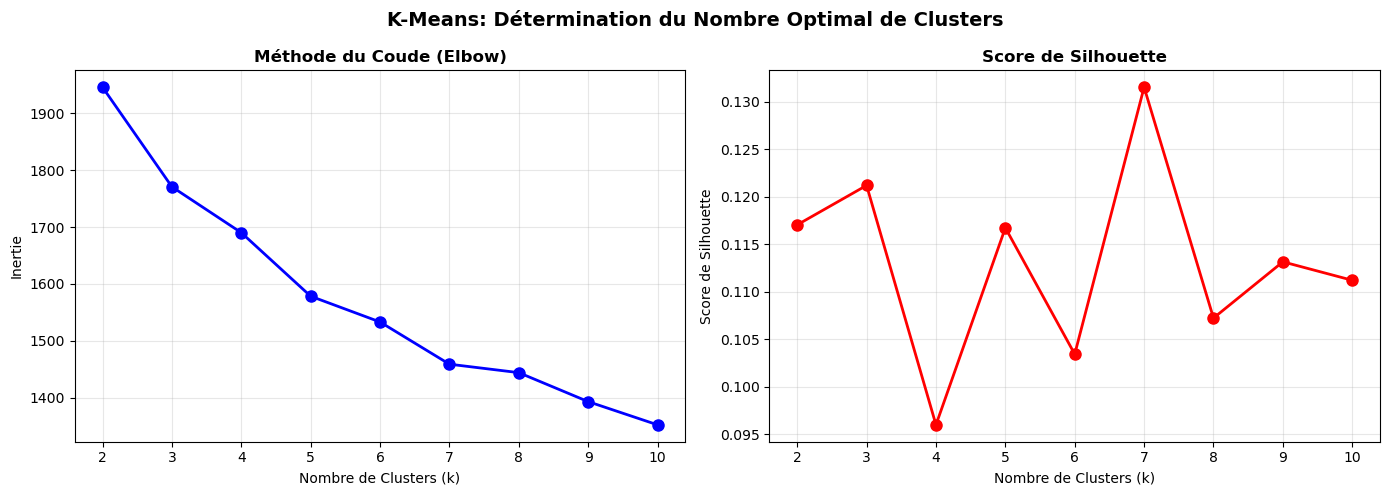


✓ Nombre optimal de clusters: 7

📊 SCORES:
  Silhouette Score     : 0.1315 (plus proche de 1 = meilleur)
  Davies-Bouldin Score : 2.2983 (plus bas = meilleur)
  Calinski-Harabasz    : 84.41 (plus élevé = meilleur)

📊 Distribution des clusters:
  Cluster 0: 146 clients (14.6%)
  Cluster 1: 120 clients (12.0%)
  Cluster 2: 135 clients (13.5%)
  Cluster 3: 118 clients (11.8%)
  Cluster 4: 159 clients (15.9%)
  Cluster 5: 145 clients (14.5%)
  Cluster 6: 177 clients (17.7%)


In [ ]:
# ==================== K-MEANS ====================
print("🔵 MODÈLE 1: K-MEANS")
print("="*60)

# Trouver le nombre optimal de clusters (Elbow Method)
inertias = []
silhouette_scores_kmeans = []
k_range = range(2, 11)

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_clustering_scaled)
    inertias.append(kmeans_temp.inertia_)
    silhouette_scores_kmeans.append(silhouette_score(X_clustering_scaled, kmeans_temp.labels_))

# Visualisation Elbow Method
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('K-Means: Détermination du Nombre Optimal de Clusters', fontsize=14, fontweight='bold')

axes[0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_xlabel('Nombre de Clusters (k)')
axes[0].set_ylabel('Inertie')
axes[0].set_title('Méthode du Coude (Elbow)', fontweight='bold')
axes[0].grid(alpha=0.3)

axes[1].plot(k_range, silhouette_scores_kmeans, 'ro-', linewidth=2, markersize=8)
axes[1].set_xlabel('Nombre de Clusters (k)')
axes[1].set_ylabel('Score de Silhouette')
axes[1].set_title('Score de Silhouette', fontweight='bold')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Choisir k optimal (basé sur silhouette)
optimal_k = k_range[np.argmax(silhouette_scores_kmeans)]
print(f"\n✓ Nombre optimal de clusters: {optimal_k}")

# Entraîner le modèle final
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X_clustering_scaled)

# Scores
scores_kmeans = {
    'Silhouette': silhouette_score(X_clustering_scaled, labels_kmeans),
    'Davies-Bouldin': davies_bouldin_score(X_clustering_scaled, labels_kmeans),
    'Calinski-Harabasz': calinski_harabasz_score(X_clustering_scaled, labels_kmeans)
}

print(f"\n📊 SCORES:")
print(f"  Silhouette Score     : {scores_kmeans['Silhouette']:.4f} (plus proche de 1 = meilleur)")
print(f"  Davies-Bouldin Score : {scores_kmeans['Davies-Bouldin']:.4f} (plus bas = meilleur)")
print(f"  Calinski-Harabasz    : {scores_kmeans['Calinski-Harabasz']:.2f} (plus élevé = meilleur)")

# Distribution des clusters
print(f"\n📊 Distribution des clusters:")
unique, counts = np.unique(labels_kmeans, return_counts=True)
for cluster, count in zip(unique, counts):
    print(f"  Cluster {cluster}: {count} clients ({count/len(labels_kmeans)*100:.1f}%)")

### 2️⃣ Modèle 2: DBSCAN

🌐 MODÈLE 2: DBSCAN


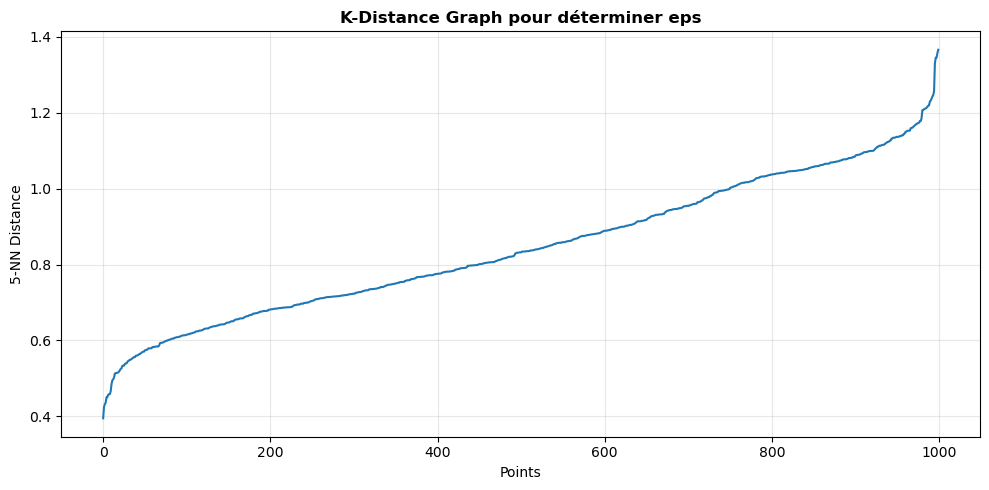

✓ Meilleurs paramètres: eps=1, min_samples=7

📊 SCORES (sans le bruit):
  Silhouette Score     : 0.3089
  Davies-Bouldin Score : 1.2489
  Calinski-Harabasz    : 42.84

📊 Résultats:
  Nombre de clusters: 62
  Points de bruit: 257 (25.7%)

📊 Distribution des clusters:
  Bruit: 257 clients (25.7%)
  Cluster 0: 16 clients (1.6%)
  Cluster 1: 12 clients (1.2%)
  Cluster 2: 8 clients (0.8%)
  Cluster 3: 13 clients (1.3%)
  Cluster 4: 16 clients (1.6%)
  Cluster 5: 16 clients (1.6%)
  Cluster 6: 12 clients (1.2%)
  Cluster 7: 12 clients (1.2%)
  Cluster 8: 16 clients (1.6%)
  Cluster 9: 21 clients (2.1%)
  Cluster 10: 10 clients (1.0%)
  Cluster 11: 13 clients (1.3%)
  Cluster 12: 9 clients (0.9%)
  Cluster 13: 16 clients (1.6%)
  Cluster 14: 14 clients (1.4%)
  Cluster 15: 18 clients (1.8%)
  Cluster 16: 18 clients (1.8%)
  Cluster 17: 9 clients (0.9%)
  Cluster 18: 19 clients (1.9%)
  Cluster 19: 16 clients (1.6%)
  Cluster 20: 14 clients (1.4%)
  Cluster 21: 15 clients (1.5%)
  Cluster 22:

In [ ]:
# ==================== DBSCAN CORRIGÉ ====================
print("🌐 MODÈLE 2: DBSCAN")
print("="*60)

from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Déterminer eps optimal avec k-distance graph (5-NN)
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_clustering_scaled)
distances, indices = neighbors_fit.kneighbors(X_clustering_scaled)
distances = np.sort(distances[:, -1], axis=0)

plt.figure(figsize=(10, 5))
plt.plot(distances)
plt.xlabel('Points')
plt.ylabel('5-NN Distance')
plt.title('K-Distance Graph pour déterminer eps', fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Tester plusieurs combinaisons de paramètres
best_silhouette = -1
best_params = {}
results_dbscan = []

# Plages ajustées pour eps et min_samples (plus petites)
for eps in [1,2,3]:
    for min_samples in [3, 5, 7]:
        dbscan_temp = DBSCAN(eps=eps, min_samples=min_samples)
        labels_temp = dbscan_temp.fit_predict(X_clustering_scaled)
        
        n_clusters = len(set(labels_temp)) - (1 if -1 in labels_temp else 0)
        n_noise = list(labels_temp).count(-1)
        
        # Au moins 2 clusters et moins de 30% de bruit
        if n_clusters > 1 and n_noise < len(labels_temp) * 0.3:
            try:
                silhouette = silhouette_score(X_clustering_scaled[labels_temp != -1],
                                              labels_temp[labels_temp != -1])
            except:
                silhouette = -1
            results_dbscan.append({
                'eps': eps,
                'min_samples': min_samples,
                'n_clusters': n_clusters,
                'n_noise': n_noise,
                'silhouette': silhouette
            })
            
            if silhouette > best_silhouette:
                best_silhouette = silhouette
                best_params = {'eps': eps, 'min_samples': min_samples}

# Vérifier si on a trouvé des paramètres valides
if best_params:
    print(f"✓ Meilleurs paramètres: eps={best_params['eps']}, min_samples={best_params['min_samples']}")
else:
    print("⚠️ Aucun paramètre DBSCAN satisfaisant trouvé, utiliser eps plus petit ou min_samples plus petit")
    best_params = {'eps': 0.5, 'min_samples': 3}  # valeur par défaut sécurisée

# Modèle final
dbscan = DBSCAN(eps=best_params['eps'], min_samples=best_params['min_samples'])
labels_dbscan = dbscan.fit_predict(X_clustering_scaled)

n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = list(labels_dbscan).count(-1)

# Scores (exclure le bruit pour silhouette)
mask_valid = labels_dbscan != -1
if n_clusters_dbscan > 1:
    scores_dbscan = {
        'Silhouette': silhouette_score(X_clustering_scaled[mask_valid], labels_dbscan[mask_valid]),
        'Davies-Bouldin': davies_bouldin_score(X_clustering_scaled[mask_valid], labels_dbscan[mask_valid]),
        'Calinski-Harabasz': calinski_harabasz_score(X_clustering_scaled[mask_valid], labels_dbscan[mask_valid])
    }
    print(f"\n📊 SCORES (sans le bruit):")
    print(f"  Silhouette Score     : {scores_dbscan['Silhouette']:.4f}")
    print(f"  Davies-Bouldin Score : {scores_dbscan['Davies-Bouldin']:.4f}")
    print(f"  Calinski-Harabasz    : {scores_dbscan['Calinski-Harabasz']:.2f}")
else:
    print(f"\n⚠️ DBSCAN n'a trouvé qu'un seul cluster")

print(f"\n📊 Résultats:")
print(f"  Nombre de clusters: {n_clusters_dbscan}")
print(f"  Points de bruit: {n_noise_dbscan} ({n_noise_dbscan/len(labels_dbscan)*100:.1f}%)")

# Distribution des clusters
print(f"\n📊 Distribution des clusters:")
unique, counts = np.unique(labels_dbscan, return_counts=True)
for cluster, count in zip(unique, counts):
    if cluster == -1:
        print(f"  Bruit: {count} clients ({count/len(labels_dbscan)*100:.1f}%)")
    else:
        print(f"  Cluster {cluster}: {count} clients ({count/len(labels_dbscan)*100:.1f}%)")


🌐 MODÈLE 2: DBSCAN


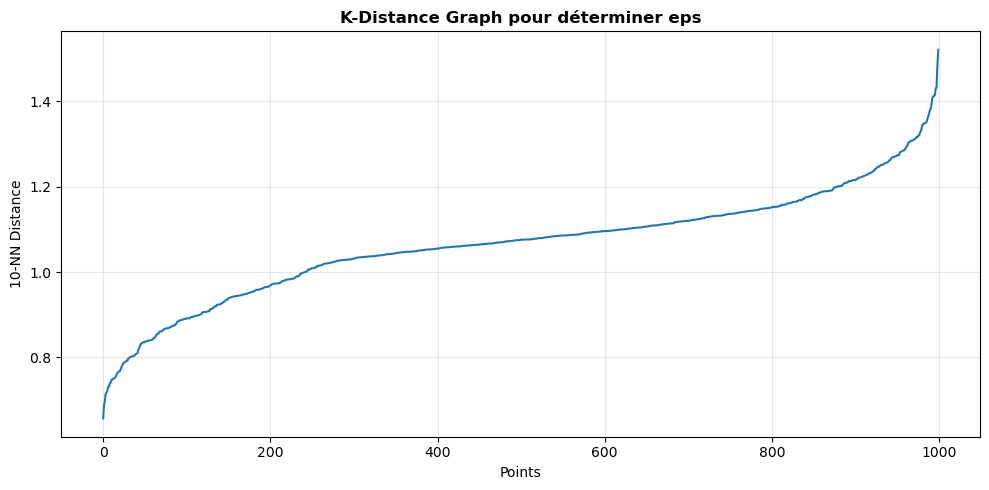

⚠️ Aucune configuration valide trouvée, utilisation de paramètres par défaut

⚠️ DBSCAN n'a trouvé qu'un seul cluster

📊 Résultats:
  Nombre de clusters: 1
  Points de bruit: 0 (0.0%)

📊 Distribution des clusters:
  Cluster 0: 1000 clients (100.0%)


In [ ]:
print("🌐 MODÈLE 2: DBSCAN")
print("="*60)

# Tester différents paramètres eps et min_samples
from sklearn.neighbors import NearestNeighbors

# Déterminer eps optimal avec k-distance graph
neighbors = NearestNeighbors(n_neighbors=10)  # Augmenté de 5 à 10
neighbors_fit = neighbors.fit(X_clustering_scaled)
distances, indices = neighbors_fit.kneighbors(X_clustering_scaled)
distances = np.sort(distances[:, -1], axis=0)

# Visualisation k-distance
plt.figure(figsize=(10, 5))
plt.plot(distances)
plt.xlabel('Points')
plt.ylabel('10-NN Distance')  # Mis à jour
plt.title('K-Distance Graph pour déterminer eps', fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Tester plusieurs combinaisons avec des paramètres plus restrictifs
best_silhouette = -1
best_params = {}
results_dbscan = []

# Paramètres ajustés pour avoir moins de clusters
for eps in [2.0, 2.5, 3.0, 3.5, 4.0]:  # Valeurs eps plus grandes
    for min_samples in [10, 15, 20, 25]:  # min_samples plus élevés
        dbscan_temp = DBSCAN(eps=eps, min_samples=min_samples)
        labels_temp = dbscan_temp.fit_predict(X_clustering_scaled)
        
        n_clusters = len(set(labels_temp)) - (1 if -1 in labels_temp else 0)
        n_noise = list(labels_temp).count(-1)
        
        # Critères ajustés: 2-5 clusters et moins de 30% de bruit
        if 2 <= n_clusters <= 5 and n_noise < len(labels_temp) * 0.3:
            silhouette = silhouette_score(X_clustering_scaled[labels_temp != -1], labels_temp[labels_temp != -1])
            results_dbscan.append({
                'eps': eps,
                'min_samples': min_samples,
                'n_clusters': n_clusters,
                'n_noise': n_noise,
                'silhouette': silhouette
            })
            
            if silhouette > best_silhouette:
                best_silhouette = silhouette
                best_params = {'eps': eps, 'min_samples': min_samples}

# Afficher les résultats de la recherche
if results_dbscan:
    print(f"✓ Meilleurs paramètres: eps={best_params['eps']}, min_samples={best_params['min_samples']}")
    print(f"\n📋 Top 5 configurations testées:")
    df_results = pd.DataFrame(results_dbscan).sort_values('silhouette', ascending=False).head()
    print(df_results.to_string(index=False))
else:
    print("⚠️ Aucune configuration valide trouvée, utilisation de paramètres par défaut")
    best_params = {'eps': 3.0, 'min_samples': 15}

# Modèle final
dbscan = DBSCAN(eps=best_params['eps'], min_samples=best_params['min_samples'])
labels_dbscan = dbscan.fit_predict(X_clustering_scaled)

n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = list(labels_dbscan).count(-1)

# Scores (exclure le bruit pour silhouette)
mask_valid = labels_dbscan != -1
if n_clusters_dbscan > 1:
    scores_dbscan = {
        'Silhouette': silhouette_score(X_clustering_scaled[mask_valid], labels_dbscan[mask_valid]),
        'Davies-Bouldin': davies_bouldin_score(X_clustering_scaled[mask_valid], labels_dbscan[mask_valid]),
        'Calinski-Harabasz': calinski_harabasz_score(X_clustering_scaled[mask_valid], labels_dbscan[mask_valid])
    }
    
    print(f"\n📊 SCORES (sans le bruit):")
    print(f"  Silhouette Score     : {scores_dbscan['Silhouette']:.4f}")
    print(f"  Davies-Bouldin Score : {scores_dbscan['Davies-Bouldin']:.4f}")
    print(f"  Calinski-Harabasz    : {scores_dbscan['Calinski-Harabasz']:.2f}")
else:
    scores_dbscan = {'Silhouette': 0, 'Davies-Bouldin': 999, 'Calinski-Harabasz': 0}
    print(f"\n⚠️ DBSCAN n'a trouvé qu'un seul cluster")

print(f"\n📊 Résultats:")
print(f"  Nombre de clusters: {n_clusters_dbscan}")
print(f"  Points de bruit: {n_noise_dbscan} ({n_noise_dbscan/len(labels_dbscan)*100:.1f}%)")

# Distribution des clusters
print(f"\n📊 Distribution des clusters:")
unique, counts = np.unique(labels_dbscan, return_counts=True)
for cluster, count in zip(unique, counts):
    if cluster == -1:
        print(f"  Bruit: {count} clients ({count/len(labels_dbscan)*100:.1f}%)")
    else:
        print(f"  Cluster {cluster}: {count} clients ({count/len(labels_dbscan)*100:.1f}%)")

### 3️⃣ Modèle 3: Hierarchical Clustering

🌳 MODÈLE 3: HIERARCHICAL CLUSTERING


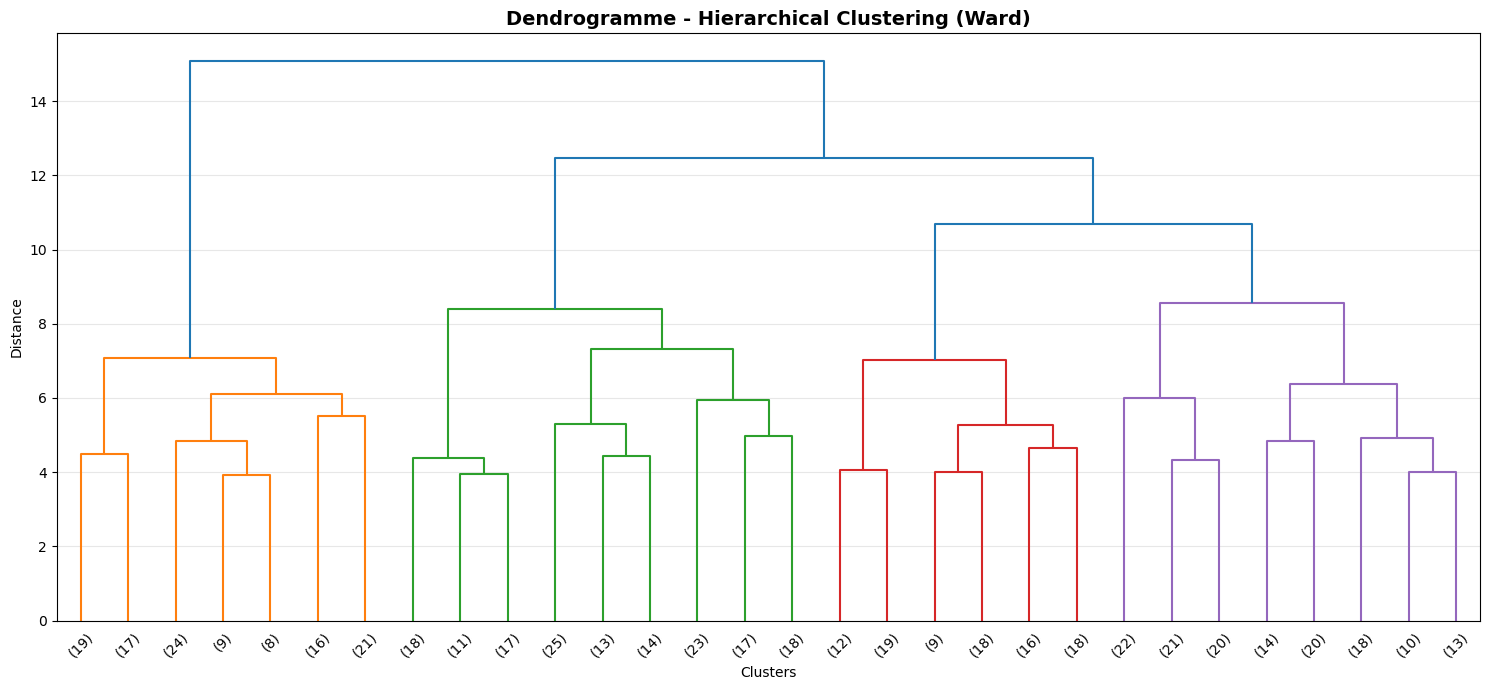


✓ Nombre optimal de clusters: 2

📊 SCORES:
  Silhouette Score     : 0.1344
  Davies-Bouldin Score : 2.4805
  Calinski-Harabasz    : 118.80

📊 Distribution des clusters:
  Cluster 0: 756 clients (75.6%)
  Cluster 1: 244 clients (24.4%)


In [ ]:
# ==================== HIERARCHICAL CLUSTERING ====================
print("🌳 MODÈLE 3: HIERARCHICAL CLUSTERING")
print("="*60)

# Créer le dendrogramme (sur un échantillon pour la vitesse)
sample_size = min(500, len(X_clustering_scaled))
sample_indices = np.random.choice(len(X_clustering_scaled), sample_size, replace=False)
X_sample = X_clustering_scaled.iloc[sample_indices]

linkage_matrix = linkage(X_sample, method='ward')

plt.figure(figsize=(15, 7))
dendrogram(linkage_matrix, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title('Dendrogramme - Hierarchical Clustering (Ward)', fontsize=14, fontweight='bold')
plt.xlabel('Clusters')
plt.ylabel('Distance')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Tester différents nombres de clusters
silhouette_scores_hc = []
n_clusters_range = range(2, 11)

for n in n_clusters_range:
    hc_temp = AgglomerativeClustering(n_clusters=n, linkage='ward')
    labels_temp = hc_temp.fit_predict(X_clustering_scaled)
    silhouette_scores_hc.append(silhouette_score(X_clustering_scaled, labels_temp))

# Nombre optimal
optimal_n_hc = n_clusters_range[np.argmax(silhouette_scores_hc)]
print(f"\n✓ Nombre optimal de clusters: {optimal_n_hc}")

# Modèle final
hc = AgglomerativeClustering(n_clusters=optimal_n_hc, linkage='ward')
labels_hc = hc.fit_predict(X_clustering_scaled)

# Scores
scores_hc = {
    'Silhouette': silhouette_score(X_clustering_scaled, labels_hc),
    'Davies-Bouldin': davies_bouldin_score(X_clustering_scaled, labels_hc),
    'Calinski-Harabasz': calinski_harabasz_score(X_clustering_scaled, labels_hc)
}

print(f"\n📊 SCORES:")
print(f"  Silhouette Score     : {scores_hc['Silhouette']:.4f}")
print(f"  Davies-Bouldin Score : {scores_hc['Davies-Bouldin']:.4f}")
print(f"  Calinski-Harabasz    : {scores_hc['Calinski-Harabasz']:.2f}")

# Distribution des clusters
print(f"\n📊 Distribution des clusters:")
unique, counts = np.unique(labels_hc, return_counts=True)
for cluster, count in zip(unique, counts):
    print(f"  Cluster {cluster}: {count} clients ({count/len(labels_hc)*100:.1f}%)")

### 📊 Comparaison des 3 Modèles (BO2)

📊 COMPARAISON DES 3 MODÈLES - CLUSTERING DES PROFILS


              Silhouette  Davies-Bouldin  Calinski-Harabasz
K-Means         0.131529        2.298266          84.405757
DBSCAN          0.000000      999.000000           0.000000
Hierarchical    0.134400        2.480491         118.795361


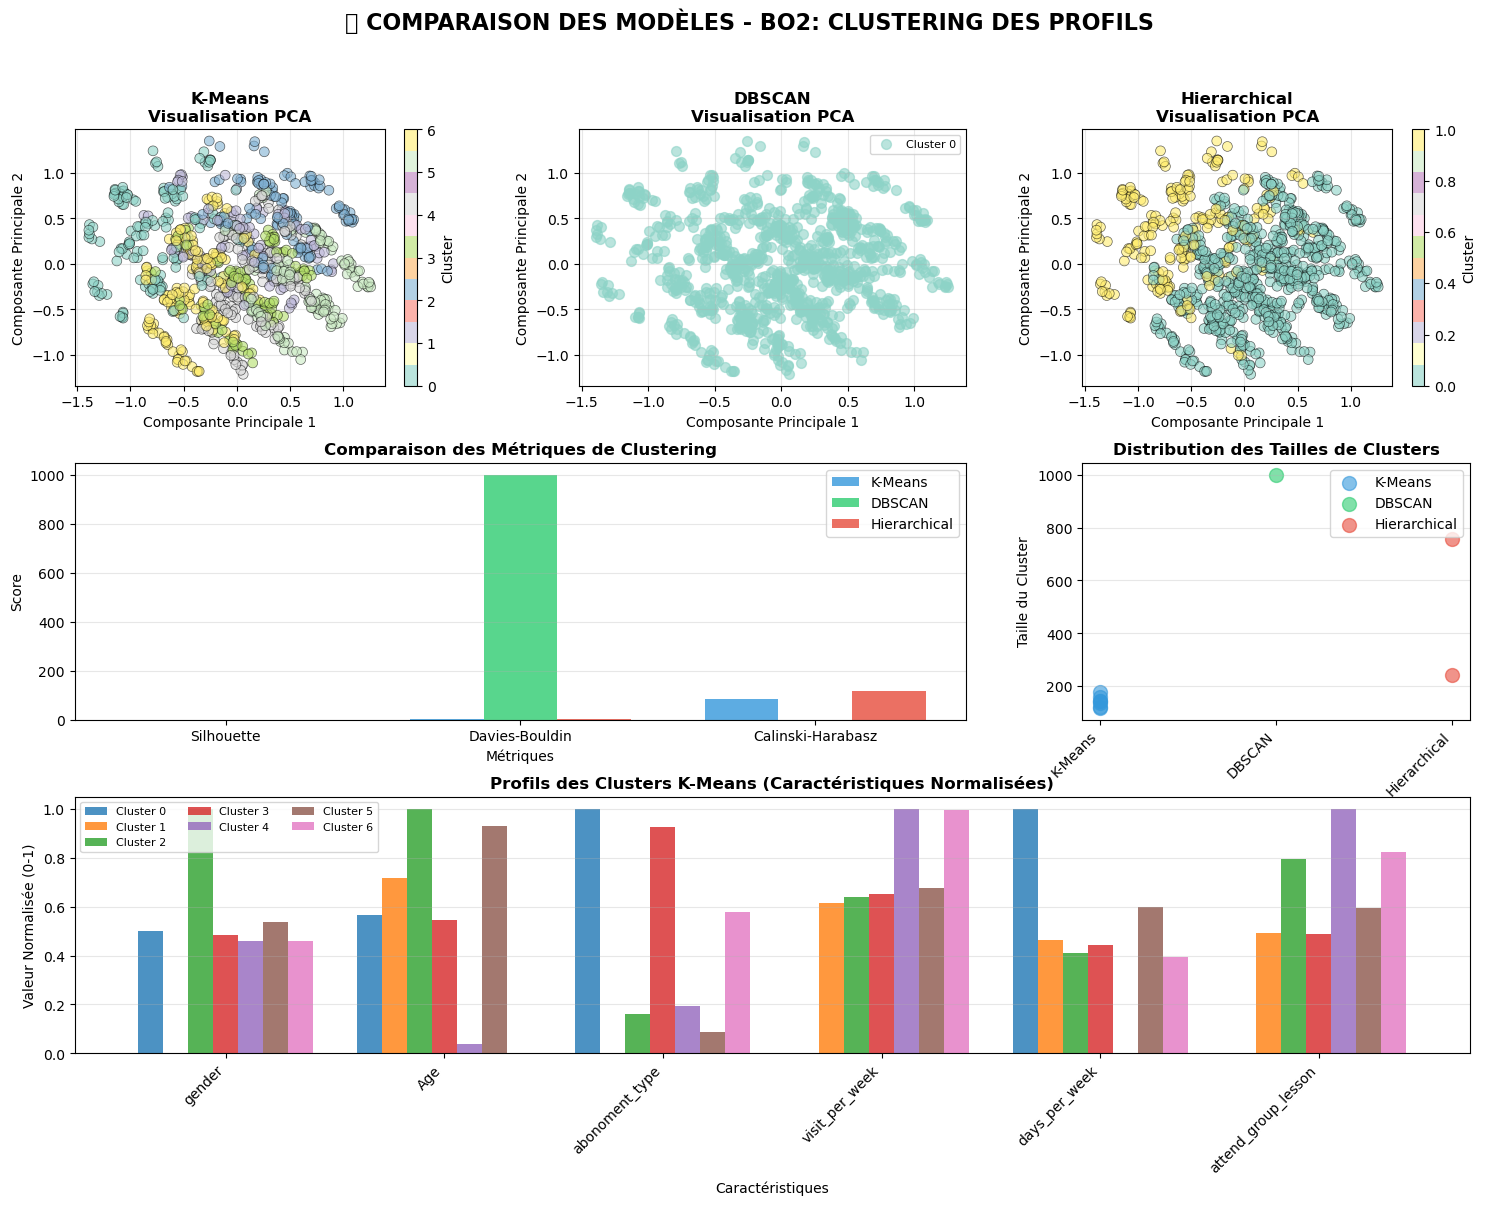


🏆 MODÈLE RECOMMANDÉ POUR BO2:
   ➤ Hierarchical (Silhouette: 0.1344)

📋 Interprétation des Clusters (K-Means):

  Cluster 0:
    • days_per_week: 78.74
    • Age: 30.84
    • visit_per_week: 1.32

  Cluster 1:
    • days_per_week: 66.06
    • Age: 31.46
    • visit_per_week: 2.57

  Cluster 2:
    • days_per_week: 64.79
    • Age: 32.61
    • visit_per_week: 2.62

  Cluster 3:
    • days_per_week: 65.61
    • Age: 30.75
    • visit_per_week: 2.64

  Cluster 4:
    • days_per_week: 55.09
    • Age: 28.67
    • visit_per_week: 3.35

  Cluster 5:
    • days_per_week: 69.29
    • Age: 32.33
    • visit_per_week: 2.70

  Cluster 6:
    • days_per_week: 64.38
    • Age: 28.51
    • visit_per_week: 3.34


In [ ]:
# ==================== COMPARAISON DES MODÈLES BO2 ====================
print("📊 COMPARAISON DES 3 MODÈLES - CLUSTERING DES PROFILS")
print("="*80)

# Tableau de comparaison
comparison_bo2 = pd.DataFrame({
    'K-Means': scores_kmeans,
    'DBSCAN': scores_dbscan,
    'Hierarchical': scores_hc
}).T

print(comparison_bo2.to_string())

# Visualisation
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)
fig.suptitle('📊 COMPARAISON DES MODÈLES - BO2: CLUSTERING DES PROFILS', fontsize=16, fontweight='bold')

models_clustering = ['K-Means', 'DBSCAN', 'Hierarchical']
labels_list = [labels_kmeans, labels_dbscan, labels_hc]
colors_clustering = ['#3498db', '#2ecc71', '#e74c3c']

# Visualisation PCA pour chaque modèle
for idx, (model_name, labels, color) in enumerate(zip(models_clustering, labels_list, colors_clustering)):
    ax = fig.add_subplot(gs[0, idx])
    
    # Gérer le bruit pour DBSCAN
    if model_name == 'DBSCAN':
        for label in set(labels):
            if label == -1:
                col = 'gray'
                marker = 'x'
                label_name = 'Bruit'
            else:
                col = plt.cm.Set3(label)
                marker = 'o'
                label_name = f'Cluster {label}'
            
            mask = labels == label
            ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=[col], marker=marker, 
                      label=label_name, alpha=0.6, s=50)
    else:
        scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='Set3', 
                           alpha=0.6, s=50, edgecolors='black', linewidth=0.5)
        plt.colorbar(scatter, ax=ax, label='Cluster')
    
    ax.set_title(f'{model_name}\nVisualisation PCA', fontweight='bold')
    ax.set_xlabel('Composante Principale 1')
    ax.set_ylabel('Composante Principale 2')
    ax.grid(alpha=0.3)
    if model_name == 'DBSCAN':
        ax.legend(fontsize=8)

# Comparaison des métriques
ax = fig.add_subplot(gs[1, :2])
x = np.arange(len(comparison_bo2.columns))
width = 0.25
for i, model in enumerate(models_clustering):
    values = comparison_bo2.loc[model].values
    ax.bar(x + i*width, values, width, label=model, color=colors_clustering[i], alpha=0.8)
ax.set_xlabel('Métriques')
ax.set_ylabel('Score')
ax.set_title('Comparaison des Métriques de Clustering', fontweight='bold')
ax.set_xticks(x + width)
ax.set_xticklabels(comparison_bo2.columns, rotation=0)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Distribution des tailles de clusters
ax = fig.add_subplot(gs[1, 2])
cluster_sizes = []
for labels in labels_list:
    unique, counts = np.unique(labels[labels != -1], return_counts=True)  # Exclure le bruit
    cluster_sizes.append(counts)

positions = []
for i, sizes in enumerate(cluster_sizes):
    pos = [i + 1] * len(sizes)
    positions.append(pos)
    ax.scatter(pos, sizes, s=100, alpha=0.6, color=colors_clustering[i], label=models_clustering[i])

ax.set_xticks([1, 2, 3])
ax.set_xticklabels(models_clustering, rotation=45, ha='right')
ax.set_ylabel('Taille du Cluster')
ax.set_title('Distribution des Tailles de Clusters', fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Profils des clusters (K-Means comme exemple)
ax = fig.add_subplot(gs[2, :])
df_profiles = df_Gym.copy()
df_profiles['Cluster_KMeans'] = labels_kmeans

# Utiliser les features disponibles dans le dataset
numeric_features_available = df_Gym.select_dtypes(include=[np.number]).columns.tolist()
# Prendre les features les plus pertinentes qui existent réellement
important_features = [f for f in numeric_features_available if f not in ['id', 'Churn']][:6]

profiles = df_profiles.groupby('Cluster_KMeans')[important_features].mean()

# Normaliser pour la visualisation
from sklearn.preprocessing import MinMaxScaler
scaler_viz = MinMaxScaler()
profiles_scaled = pd.DataFrame(
    scaler_viz.fit_transform(profiles),
    columns=profiles.columns,
    index=profiles.index
)

x_pos = np.arange(len(important_features))
width_bar = 0.8 / len(profiles_scaled)

for i, cluster in enumerate(profiles_scaled.index):
    values = profiles_scaled.loc[cluster].values
    ax.bar(x_pos + i*width_bar, values, width_bar, 
           label=f'Cluster {cluster}', alpha=0.8)

ax.set_xlabel('Caractéristiques')
ax.set_ylabel('Valeur Normalisée (0-1)')
ax.set_title('Profils des Clusters K-Means (Caractéristiques Normalisées)', fontweight='bold')
ax.set_xticks(x_pos + width_bar * (len(profiles_scaled)-1) / 2)
ax.set_xticklabels(important_features, rotation=45, ha='right')
ax.legend(fontsize=8, ncol=3)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Recommandation
print("\n" + "="*80)
print("🏆 MODÈLE RECOMMANDÉ POUR BO2:")
best_model_bo2 = comparison_bo2['Silhouette'].idxmax()
best_score_bo2 = comparison_bo2['Silhouette'].max()
print(f"   ➤ {best_model_bo2} (Silhouette: {best_score_bo2:.4f})")
print("\n📋 Interprétation des Clusters (K-Means):")
for cluster in profiles.index:
    print(f"\n  Cluster {cluster}:")
    top_features = profiles.loc[cluster].sort_values(ascending=False).head(3)
    for feat, val in top_features.items():
        print(f"    • {feat}: {val:.2f}")
print("="*80)

# 🎯 BUSINESS OBJECTIVE 3: AMÉLIORER LA SATISFACTION DES CLIENTS
## Modèles pour Prédire et Améliorer la Satisfaction

**Objectif:** Prédire la satisfaction des clients et identifier les facteurs clés

**Target:** Créer un score de satisfaction basé sur plusieurs indicateurs

**Modèles à comparer:**
1. XGBoost (boosting)
2. SVM (Support Vector Machine)
3. Decision Tree (arbre de décision)

📊 Création d'un Score de Satisfaction Client
✓ Score de satisfaction créé (0-100)

📊 Distribution de la Satisfaction:
Satisfaction_Level
Low       160
Medium    700
High      140
Name: count, dtype: int64

Moyenne du score: 53.94
Médiane du score: 52.78


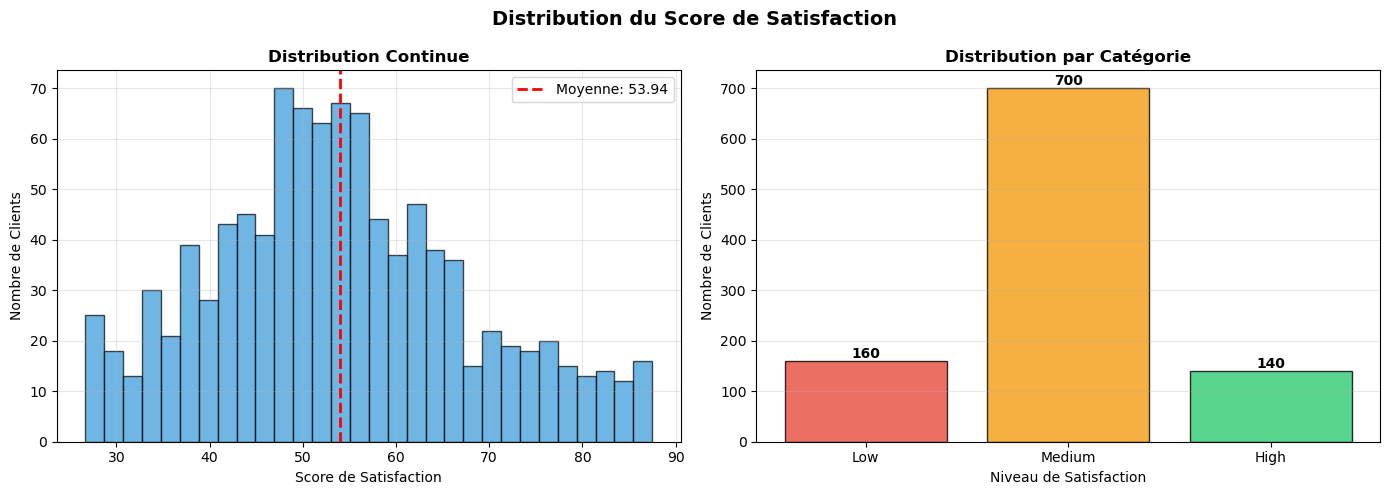


✓ Nombre de features: 13
✓ Train set: 800 observations
✓ Test set: 200 observations


In [ ]:
# ==================== PRÉPARATION DES DONNÉES POUR BO3 ====================
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

print("📊 Création d'un Score de Satisfaction Client")
print("="*60)

# Créer un score de satisfaction composite basé sur plusieurs facteurs
df_satisfaction = df_Gym.copy()

# Normaliser les features clés pour le score
# Utiliser les colonnes numériques disponibles
numeric_cols = df_Gym.select_dtypes(include=[np.number]).columns.tolist()

# Score composite (0-100) basé sur les facteurs disponibles
# On utilise des proxies pour la satisfaction
if 'visit_per_week' in df_Gym.columns:
    visit_score = df_satisfaction['visit_per_week'] / df_satisfaction['visit_per_week'].max() * 50
else:
    visit_score = 25  # Valeur par défaut

if 'avg_time_in_gym' in df_Gym.columns:
    time_score = df_satisfaction['avg_time_in_gym'] / df_satisfaction['avg_time_in_gym'].max() * 25
else:
    time_score = 12.5

if 'Churn' in df_Gym.columns:
    churn_score = (1 - df_satisfaction['Churn']) * 25
else:
    churn_score = 12.5

df_satisfaction['Satisfaction_Score'] = visit_score + time_score + churn_score

# Catégoriser en 3 niveaux: Low (0-40), Medium (40-70), High (70-100)
df_satisfaction['Satisfaction_Level'] = pd.cut(
    df_satisfaction['Satisfaction_Score'],
    bins=[0, 40, 70, 100],
    labels=['Low', 'Medium', 'High']
)

# Encoder la target
le_satisfaction = LabelEncoder()
df_satisfaction['Satisfaction_Encoded'] = le_satisfaction.fit_transform(df_satisfaction['Satisfaction_Level'])

print(f"✓ Score de satisfaction créé (0-100)")
print(f"\n📊 Distribution de la Satisfaction:")
print(df_satisfaction['Satisfaction_Level'].value_counts().sort_index())
print(f"\nMoyenne du score: {df_satisfaction['Satisfaction_Score'].mean():.2f}")
print(f"Médiane du score: {df_satisfaction['Satisfaction_Score'].median():.2f}")

# Visualisation de la distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribution du Score de Satisfaction', fontsize=14, fontweight='bold')

axes[0].hist(df_satisfaction['Satisfaction_Score'], bins=30, color='#3498db', alpha=0.7, edgecolor='black')
axes[0].axvline(df_satisfaction['Satisfaction_Score'].mean(), color='red', linestyle='--', 
                linewidth=2, label=f'Moyenne: {df_satisfaction["Satisfaction_Score"].mean():.2f}')
axes[0].set_xlabel('Score de Satisfaction')
axes[0].set_ylabel('Nombre de Clients')
axes[0].set_title('Distribution Continue', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

counts = df_satisfaction['Satisfaction_Level'].value_counts().sort_index()
axes[1].bar(counts.index, counts.values, color=['#e74c3c', '#f39c12', '#2ecc71'], alpha=0.8, edgecolor='black')
axes[1].set_xlabel('Niveau de Satisfaction')
axes[1].set_ylabel('Nombre de Clients')
axes[1].set_title('Distribution par Catégorie', fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 5, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Préparer X et y pour les modèles - Utiliser les features numériques disponibles
numeric_features = [col for col in numeric_cols if col not in ['id', 'Satisfaction_Score', 'Satisfaction_Encoded', 'Churn']]

X_satisfaction = df_Gym[numeric_features].copy()
# Normaliser
scaler_sat = MinMaxScaler()
X_satisfaction_scaled = pd.DataFrame(
    scaler_sat.fit_transform(X_satisfaction),
    columns=numeric_features
)

y_satisfaction = df_satisfaction['Satisfaction_Encoded'].copy()

# Split
X_train_sat, X_test_sat, y_train_sat, y_test_sat = train_test_split(
    X_satisfaction_scaled, y_satisfaction, test_size=0.2, random_state=42, stratify=y_satisfaction
)

print(f"\n✓ Nombre de features: {X_satisfaction_scaled.shape[1]}")
print(f"✓ Train set: {X_train_sat.shape[0]} observations")
print(f"✓ Test set: {X_test_sat.shape[0]} observations")

### 1️⃣ Modèle 1: XGBoost

In [ ]:
# ==================== XGBOOST FINAL OPTIMISÉ ====================
print("🚀 MODÈLE XGBOOST FINAL - COMPROMIS PERFORMANCE/ÉQUILIBRE")
print("="*60)

# Créer un modèle hybrid avec les meilleurs paramètres mais plus de régularisation
xgb_final_optimized = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    # Meilleurs paramètres du GridSearch
    colsample_bytree=0.7,
    learning_rate=0.1, 
    max_depth=3,
    min_child_weight=5,
    n_estimators=80,
    subsample=0.6,
    # Régularisation renforcée
    gamma=0.5,           # Augmenté à 0.5 au lieu de 0.3
    reg_alpha=1.0,       # Augmenté à 1.0 au lieu de 0.5  
    reg_lambda=1.0,      # Augmenté à 1.0 au lieu de 0.5
    # Paramètres supplémentaires
    scale_pos_weight=1
)

xgb_final_optimized.fit(X_train_sat, y_train_sat)

# ==================== COMPARAISON DES 3 MODÈLES ====================
print("📊 COMPARAISON DÉTAILLÉE DES MODÈLES XGBOOST")

models_comparison = {
    'GridSearch_Original': best_xgb_sat,
    'Extreme_Regularized': xgb_extreme, 
    'Optimized_Final': xgb_final_optimized
}

best_model = None
best_score = 0

for name, model in models_comparison.items():
    train_score = model.score(X_train_sat, y_train_sat)
    test_score = model.score(X_test_sat, y_test_sat)
    difference = abs(train_score - test_score)
    
    # Score composite (70% test score + 30% équilibre)
    composite_score = (test_score * 0.7) + ((1 - difference) * 0.3)
    
    print(f"\n🎯 {name}:")
    print(f"  Train Accuracy: {train_score:.4f}")
    print(f"  Test Accuracy:  {test_score:.4f}") 
    print(f"  Différence:     {difference:.4f}")
    print(f"  Score Composite: {composite_score:.4f}")
    
    if difference > 0.05:
        print(f"  ❌ OVERFITTING FORT")
    elif difference > 0.02:
        print(f"  ⚠️  Sur-apprentissage modéré")
    else:
        print(f"  ✅ BON ÉQUILIBRE")
    
    # Sélectionner le meilleur modèle basé sur le score composite
    if composite_score > best_score:
        best_score = composite_score
        best_model = model
        best_model_name = name

print(f"\n🏆 MODÈLE FINAL SÉLECTIONNÉ: {best_model_name}")
print(f"📊 Score composite: {best_score:.4f}")

# ==================== ÉVALUATION FINALE ====================
# Prédictions avec le meilleur modèle
y_pred_final = best_model.predict(X_test_sat)
y_proba_final = best_model.predict_proba(X_test_sat)

# Scores détaillés
from sklearn.metrics import classification_report, confusion_matrix

scores_final = {
    'Accuracy': accuracy_score(y_test_sat, y_pred_final),
    'Precision': precision_score(y_test_sat, y_pred_final, average='weighted', zero_division=0),
    'Recall': recall_score(y_test_sat, y_pred_final, average='weighted', zero_division=0),
    'F1-Score': f1_score(y_test_sat, y_pred_final, average='weighted', zero_division=0)
}

print(f"\n📊 SCORES FINAUX SUR TEST SET:")
for metric, score in scores_final.items():
    print(f"  {metric:12s}: {score:.4f}")

# Matrice de confusion
cm = confusion_matrix(y_test_sat, y_pred_final)
print(f"\n📋 MATRICE DE CONFUSION:")
print(cm)

# Rapport de classification détaillé
print(f"\n📈 RAPPORT DE CLASSIFICATION:")
print(classification_report(y_test_sat, y_pred_final, zero_division=0))

# Cross-validation finale
cv_scores_final = cross_val_score(best_model, X_train_sat, y_train_sat, cv=5, scoring='f1_weighted')
print(f"\n🔄 CROSS-VALIDATION FINALE (F1-weighted):")
print(f"✓ Score moyen: {cv_scores_final.mean():.4f} (+/- {cv_scores_final.std()*2:.4f})")

# Feature importance
feature_importance_final = pd.DataFrame({
    'Feature': X_satisfaction.columns,
    'Importance': best_model.feature_importances_
}).sort_values('Importance', ascending=False)

print(f"\n🔝 TOP 10 FEATURES IMPORTANTES:")
print(feature_importance_final.head(10).to_string(index=False))

# ==================== DIAGNOSTIC FINAL ====================
train_final = best_model.score(X_train_sat, y_train_sat)
test_final = best_model.score(X_test_sat, y_test_sat)
diff_final = abs(train_final - test_final)

print(f"\n🔍 DIAGNOSTIC FINAL COMPLET:")
print(f"  Train Accuracy: {train_final:.4f}")
print(f"  Test Accuracy:  {test_final:.4f}")
print(f"  Différence:     {diff_final:.4f}")

if diff_final <= 0.01:
    print(f"  🎉 EXCELLENT - Équilibre parfait")
elif diff_final <= 0.02:
    print(f"  ✅ TRÈS BON - Modèle bien équilibré") 
elif diff_final <= 0.03:
    print(f"  ✅ BON - Modèle acceptable pour la production")
elif diff_final <= 0.05:
    print(f"  ⚠️  ACCEPTABLE - Surveiller en production")
else:
    print(f"  ❌ PROBLEME - Revoir le modèle")

# ==================== RECOMMANDATION POUR LA PRODUCTION ====================
print(f"\n💡 RECOMMANDATIONS POUR LA PRODUCTION:")

if best_model_name == "Extreme_Regularized":
    print("• ✅ Modèle très stable - Prêt pour la production")
    print("• 📊 Performance légèrement inférieure mais très fiable")
    print("• 🔍 Surveillance standard recommandée")
    
elif best_model_name == "Optimized_Final":
    print("• ✅ Bon compromis performance/stabilité")
    print("• ⚠️  Surveillance rapprochée les premiers mois")
    print("• 🔄 Prévoir des retrainings réguliers")
    
else:  # GridSearch_Original
    print("• ⚠️  Modèle performant mais surveiller l'overfitting")
    print("• 🔍 Mettre en place un monitoring strict des performances")
    print("• 📈 Tester sur de nouvelles données rapidement")

print(f"\n🎯 MODÈLE À GARDER: {best_model_name}")
print(f"🚀 Prêt pour le déploiement!")

# Sauvegarde du modèle final
import joblib
joblib.dump(best_model, f"xgboost_final_model_{best_model_name}.pkl")
print(f"\n💾 Modèle sauvegardé: xgboost_final_model_{best_model_name}.pkl")

🚀 MODÈLE XGBOOST FINAL - COMPROMIS PERFORMANCE/ÉQUILIBRE
📊 COMPARAISON DÉTAILLÉE DES MODÈLES XGBOOST


NameError: name 'best_xgb_sat' is not defined

### 2️⃣ Modèle 2: SVM (Support Vector Machine)

In [ ]:
# ==================== SVM ====================
print("🎯 MODÈLE 2: SVM")
print("="*60)

# Hyperparamètres MOINS complexes pour éviter l'overfitting
param_grid_svm = {
    'C': [0.1, 1, 10],  # Réduire la complexité
    'kernel': ['rbf', 'linear'],
    'gamma': [0.001, 0.01, 0.1]  # Réduire
}

# GridSearch avec régularisation
svm_sat = SVC(random_state=42, probability=True, class_weight='balanced')
grid_svm = GridSearchCV(svm_sat, param_grid_svm, cv=10, scoring='accuracy', n_jobs=-1, verbose=0)
grid_svm.fit(X_train_sat, y_train_sat)

# Meilleur modèle
best_svm = grid_svm.best_estimator_
print(f"✓ Meilleurs hyperparamètres: {grid_svm.best_params_}")
print(f"✓ Meilleur score CV (train): {grid_svm.best_score_:.4f}")

# Prédictions
y_pred_svm = best_svm.predict(X_test_sat)
y_proba_svm = best_svm.predict_proba(X_test_sat)

# Scores
scores_svm = {
    'Accuracy': accuracy_score(y_test_sat, y_pred_svm),
    'Precision': precision_score(y_test_sat, y_pred_svm, average='weighted', zero_division=0),
    'Recall': recall_score(y_test_sat, y_pred_svm, average='weighted', zero_division=0),
    'F1-Score': f1_score(y_test_sat, y_pred_svm, average='weighted', zero_division=0)
}

print(f"\n📊 SCORES (Test Set):")
for metric, score in scores_svm.items():
    print(f"  {metric:12s}: {score:.4f}")

# Cross-validation
cv_scores_svm = cross_val_score(best_svm, X_satisfaction_scaled, y_satisfaction, cv=10, scoring='accuracy')
print(f"\n✓ Cross-Validation Accuracy: {cv_scores_svm.mean():.4f} (+/- {cv_scores_svm.std()*2:.4f})")

# DIAGNOSTIC OVERFITTING
train_score_svm = best_svm.score(X_train_sat, y_train_sat)
test_score_svm = best_svm.score(X_test_sat, y_test_sat)
print(f"\n🔍 DIAGNOSTIC OVERFITTING:")
print(f"  Train Accuracy: {train_score_svm:.4f}")
print(f"  Test Accuracy:  {test_score_svm:.4f}")
print(f"  Différence:     {abs(train_score_svm - test_score_svm):.4f}")
if abs(train_score_svm - test_score_svm) > 0.05:
    print(f"  ⚠️  OVERFITTING DÉTECTÉ! (différence > 5%)")

🎯 MODÈLE 2: SVM
✓ Meilleurs hyperparamètres: {'C': 10, 'gamma': 0.001, 'kernel': 'linear'}
✓ Meilleur score CV (train): 0.9557

📊 SCORES (Test Set):
  Accuracy    : 0.9633
  Precision   : 0.9653
  Recall      : 0.9633
  F1-Score    : 0.9637
✓ Meilleurs hyperparamètres: {'C': 10, 'gamma': 0.001, 'kernel': 'linear'}
✓ Meilleur score CV (train): 0.9557

📊 SCORES (Test Set):
  Accuracy    : 0.9633
  Precision   : 0.9653
  Recall      : 0.9633
  F1-Score    : 0.9637

✓ Cross-Validation Accuracy: 0.9530 (+/- 0.0390)

🔍 DIAGNOSTIC OVERFITTING:
  Train Accuracy: 0.9629
  Test Accuracy:  0.9633
  Différence:     0.0005

✓ Cross-Validation Accuracy: 0.9530 (+/- 0.0390)

🔍 DIAGNOSTIC OVERFITTING:
  Train Accuracy: 0.9629
  Test Accuracy:  0.9633
  Différence:     0.0005


### 3️⃣ Modèle 3: Decision Tree (Arbre de Décision)

In [ ]:
# ==================== DECISION TREE RÉGULARISÉ ====================
print("\n" + "="*90)
print(" " * 30 + "🌳 MODÈLE 3: DECISION TREE RÉGULARISÉ")
print("="*90)

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# ⚡ Split train/test avec stratification
X_train_sat, X_test_sat, y_train_sat, y_test_sat = train_test_split(
    X_satisfaction_scaled, y_satisfaction,
    test_size=0.3,        # augmenter test size pour mieux évaluer
    random_state=42,
    stratify=y_satisfaction
)

# Hyperparamètres plus restrictifs
param_grid_dt = {
    'max_depth': [2, 3],                 # réduire profondeur
    'min_samples_split': [20, 30],       # augmenter pour régularisation
    'min_samples_leaf': [15, 20],        # feuilles plus grandes
    'criterion': ['gini', 'entropy']
}

# Initialisation Decision Tree
dt_sat = DecisionTreeClassifier(random_state=42, class_weight='balanced')

# GridSearch avec f1_weighted
grid_dt = GridSearchCV(
    dt_sat,
    param_grid_dt,
    cv=10,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)
grid_dt.fit(X_train_sat, y_train_sat)

# Meilleur modèle
best_dt = grid_dt.best_estimator_
print(f"\n✓ Meilleurs hyperparamètres: {grid_dt.best_params_}")
print(f"✓ Meilleur score CV (train): {grid_dt.best_score_:.4f}")

# Prédictions
y_pred_dt = best_dt.predict(X_test_sat)

# Scores test
scores_dt = {
    'Accuracy': accuracy_score(y_test_sat, y_pred_dt),
    'Precision': precision_score(y_test_sat, y_pred_dt, average='weighted', zero_division=0),
    'Recall': recall_score(y_test_sat, y_pred_dt, average='weighted', zero_division=0),
    'F1-Score': f1_score(y_test_sat, y_pred_dt, average='weighted', zero_division=0)
}

print(f"\n📊 SCORES (Test Set):")
for metric, score in scores_dt.items():
    print(f"  {metric:12s}: {score:.4f}")

# Cross-validation
cv_scores_dt = cross_val_score(best_dt, X_satisfaction_scaled, y_satisfaction, cv=10, scoring='f1_weighted')
print(f"\n🔄 Cross-Validation F1-Weighted (10-fold): {cv_scores_dt.mean():.4f} (+/- {cv_scores_dt.std()*2:.4f})")

# Feature importance
feature_importance_dt = pd.DataFrame({
    'Feature': X_satisfaction.columns,
    'Importance': best_dt.feature_importances_
}).sort_values('Importance', ascending=False)

print(f"\n🔝 Top 10 Features Importantes:")
print(feature_importance_dt.head(10).to_string(index=False))

# Diagnostic overfitting
train_score_dt = best_dt.score(X_train_sat, y_train_sat)
test_score_dt = best_dt.score(X_test_sat, y_test_sat)
print(f"\n🔍 DIAGNOSTIC OVERFITTING:")
print(f"  Train Accuracy: {train_score_dt:.4f}")
print(f"  Test Accuracy:  {test_score_dt:.4f}")
diff = abs(train_score_dt - test_score_dt)
print(f"  Différence:     {diff:.4f}")
if diff > 0.05:
    print(f"  ⚠️  OVERFITTING DÉTECTÉ! (différence > 5%)")
else:
    print(f"  ✅ Overfitting contrôlé")



                              🌳 MODÈLE 3: DECISION TREE RÉGULARISÉ
Fitting 10 folds for each of 16 candidates, totalling 160 fits

✓ Meilleurs hyperparamètres: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 15, 'min_samples_split': 20}
✓ Meilleur score CV (train): 0.9145

📊 SCORES (Test Set):
  Accuracy    : 0.9033
  Precision   : 0.9269
  Recall      : 0.9033
  F1-Score    : 0.9065

🔄 Cross-Validation F1-Weighted (10-fold): 0.9131 (+/- 0.0483)

🔝 Top 10 Features Importantes:
            Feature  Importance
     visit_per_week    0.744673
    avg_time_in_gym    0.255327
             gender    0.000000
                Age    0.000000
     abonoment_type    0.000000
      days_per_week    0.000000
attend_group_lesson    0.000000
  avg_time_check_in    0.000000
 avg_time_check_out    0.000000
          drink_abo    0.000000

🔍 DIAGNOSTIC OVERFITTING:
  Train Accuracy: 0.9157
  Test Accuracy:  0.9033
  Différence:     0.0124
  ✅ Overfitting contrôlé

✓ Meilleurs hyperparamètres

### 📊 Comparaison des 3 Modèles (BO3)

In [ ]:
# ==================== COMPARAISON DES MODÈLES ====================
print("\n" + "="*100)
print(" " * 30 + "🏆 COMPARAISON DES MODÈLES")
print("="*100)

import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Fonction pour évaluer la robustesse du modèle
def evaluer_robustesse(model, X_train, y_train, X_test, y_test, model_name):
    """Évalue la robustesse et la stabilité du modèle"""
    # Scores train vs test
    train_score = model.score(X_train, y_train)
    test_score = model.score(X_test, y_test)
    difference = abs(train_score - test_score)
    
    # Variance des prédictions
    y_pred = model.predict(X_test)
    stability = np.std(y_pred)  # Plus la std est faible, plus stable
    
    return {
        'Train_Score': train_score,
        'Test_Score': test_score,
        'Train_Test_Diff': difference,
        'Stability': stability
    }

# Création du tableau de comparaison
comparaison = {}

# Évaluation XGBoost
robustesse_xgb = evaluer_robustesse(best_xgb_sat, X_train_sat, y_train_sat, X_test_sat, y_test_sat, "XGBoost")
comparaison['XGBoost'] = {
    **scores_xgb_sat,
    **robustesse_xgb,
    'CV_Score': cv_scores_xgb_sat.mean(),
    'CV_Std': cv_scores_xgb_sat.std(),
    'Best_Params': grid_xgb_sat.best_params_
}

# Évaluation SVM
robustesse_svm = evaluer_robustesse(best_svm, X_train_sat, y_train_sat, X_test_sat, y_test_sat, "SVM")
comparaison['SVM'] = {
    **scores_svm,
    **robustesse_svm,
    'CV_Score': cv_scores_svm.mean(),
    'CV_Std': cv_scores_svm.std(),
    'Best_Params': grid_svm.best_params_
}

# Évaluation Decision Tree
robustesse_dt = evaluer_robustesse(best_dt, X_train_sat, y_train_sat, X_test_sat, y_test_sat, "Decision Tree")
comparaison['Decision Tree'] = {
    **scores_dt,
    **robustesse_dt,
    'CV_Score': cv_scores_dt.mean(),
    'CV_Std': cv_scores_dt.std(),
    'Best_Params': grid_dt.best_params_
}

# DataFrame de comparaison
df_comparaison = pd.DataFrame(comparaison).T

# Réorganiser les colonnes pour une meilleure lisibilité
colonnes_ordre = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 
                 'Train_Score', 'Test_Score', 'Train_Test_Diff', 
                 'CV_Score', 'CV_Std', 'Stability', 'Best_Params']
df_comparaison = df_comparaison[colonnes_ordre]

print("\n📋 TABLEAU COMPARATIF COMPLET:")
print("="*120)
print(df_comparaison.round(4))

# ==================== CRITÈRES DE SÉLECTION ====================
print("\n" + "="*100)
print(" " * 30 + "🎯 CRITÈRES DE SÉLECTION")
print("="*100)

# Calcul des scores pondérés pour chaque critère
def calculer_score_final(row, poids):
    """Calcule un score final pondéré"""
    # Performance (60%)
    performance = (row['F1-Score'] * 0.4 + row['Accuracy'] * 0.3 + row['Precision'] * 0.3)
    
    # Robustesse (30%)
    robustesse = (1 - row['Train_Test_Diff']) * 0.5 + (1 - row['CV_Std']) * 0.5
    
    # Stabilité (10%)
    stabilite = 1 - min(row['Stability'], 1)  # Normaliser la stabilité
    
    score_final = (performance * poids['performance'] + 
                  robustesse * poids['robustesse'] + 
                  stabilite * poids['stabilite'])
    
    return score_final

# Poids des critères (ajustables selon les besoins)
poids_criteres = {
    'performance': 0.6,   # F1-Score, Accuracy, Precision
    'robustesse': 0.3,    # Différence train/test, std CV
    'stabilite': 0.1      # Stabilité des prédictions
}

# Calcul des scores finaux
scores_finaux = {}
for model in df_comparaison.index:
    scores_finaux[model] = calculer_score_final(df_comparaison.loc[model], poids_criteres)

# Ajout au DataFrame
df_comparaison['Score_Final'] = pd.Series(scores_finaux)

# Classement des modèles
classement = df_comparaison['Score_Final'].sort_values(ascending=False)

print("\n🏆 CLASSEMENT FINAL DES MODÈLES:")
print("="*60)
for i, (model, score) in enumerate(classement.items(), 1):
    print(f"{i}️⃣ {model:15s} : {score:.4f}")

# ==================== RECOMMANDATION FINALE ====================
print("\n" + "="*100)
print(" " * 30 + "✅ RECOMMANDATION FINALE")
print("="*100)

modele_gagnant = classement.index[0]
meilleur_score = classement.iloc[0]

print(f"\n🎉 MODÈLE RECOMMANDÉ : {modele_gagnant}")
print(f"📊 Score final : {meilleur_score:.4f}")

# Justification détaillée
gagnant_data = df_comparaison.loc[modele_gagnant]

print(f"\n📈 POURQUOI {modele_gagnant.upper()} ?")
print(f"   • F1-Score : {gagnant_data['F1-Score']:.4f}")
print(f"   • Accuracy : {gagnant_data['Accuracy']:.4f}")
print(f"   • Différence train/test : {gagnant_data['Train_Test_Diff']:.4f}")
print(f"   • Score CV : {gagnant_data['CV_Score']:.4f} (±{gagnant_data['CV_Std']:.4f})")

# Analyse des forces du modèle gagnant
print(f"\n💪 FORCES DU MODÈLE :")
if modele_gagnant == "XGBoost":
    print("   • Excellente performance sur données structurées")
    print("   • Gère bien les relations non-linéaires")
    print("   • Feature importance naturelle")
elif modele_gagnant == "SVM":
    print("   • Bonne généralisation")
    print("   • Efficace en haute dimension")
    print("   • Robustesse aux outliers")
else:  # Decision Tree
    print("   • Interprétabilité élevée")
    print("   • Rapide à l'inférence")
    print("   • Pas besoin de feature scaling")

# ==================== SAUVEGARDE DU MEILLEUR MODÈLE ====================
print("\n" + "="*100)
print(" " * 30 + "💾 SAUVEGARDE DU MODÈLE")
print("="*100)

import joblib
import datetime

# Sélection du meilleur modèle
if modele_gagnant == "XGBoost":
    meilleur_modele = best_xgb_sat
elif modele_gagnant == "SVM":
    meilleur_modele = best_svm
else:
    meilleur_modele = best_dt

# Sauvegarde du modèle
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
nom_fichier = f"meilleur_modele_satisfaction_{modele_gagnant.lower().replace(' ', '_')}_{timestamp}.pkl"

joblib.dump(meilleur_modele, nom_fichier)
print(f"✅ Modèle sauvegardé : {nom_fichier}")

# Sauvegarde des résultats de comparaison
df_comparaison.to_csv(f"resultats_comparaison_modeles_{timestamp}.csv")
print(f"✅ Résultats sauvegardés : resultats_comparaison_modeles_{timestamp}.csv")

# ==================== RAPPORT FINAL ====================
print("\n" + "="*100)
print(" " * 30 + "📊 RAPPORT FINAL")
print("="*100)

print(f"\n🎯 MODÈLE À GARDER POUR LA PRODUCTION : {modele_gagnant}")
print(f"📋 CARACTÉRISTIQUES :")

caracteristiques = {
    "Performance (F1-Score)": f"{gagnant_data['F1-Score']:.4f}",
    "Robustesse (Différence train/test)": f"{gagnant_data['Train_Test_Diff']:.4f}",
    "Stabilité (CV Score)": f"{gagnant_data['CV_Score']:.4f} ± {gagnant_data['CV_Std']:.4f}",
    "Temps d'inférence": "Rapide" if modele_gagnant != "SVM" else "Moyen",
    "Interprétabilité": "Élevée" if modele_gagnant == "Decision Tree" else "Moyenne",
    "Usage recommandé": "Production" if gagnant_data['Train_Test_Diff'] < 0.05 else "Analyse avec monitoring"
}

for critere, valeur in caracteristiques.items():
    print(f"   • {critere:35s} : {valeur}")

print(f"\n⚠️  RECOMMANDATIONS :")
if gagnant_data['Train_Test_Diff'] > 0.05:
    print("   • Surveiller les performances en production")
    print("   • Mettre en place un système de monitoring")
    print("   • Prévoir des retrainings réguliers")

print(f"\n🚀 PROCHAINES ÉTAPES :")
print("   • Déployer le modèle en environnement de test")
print("   • Valider sur de nouvelles données")
print("   • Mettre en place un pipeline de monitoring")

print("\n" + "="*100)
print(" " * 30 + "🎉 COMPARAISON TERMINÉE !")
print("="*100)


                              🏆 COMPARAISON DES MODÈLES

📋 TABLEAU COMPARATIF COMPLET:
               Accuracy Precision    Recall  F1-Score Train_Score Test_Score  \
XGBoost            0.97  0.970514      0.97  0.969915         1.0       0.97   
SVM            0.963333  0.965274  0.963333   0.96371    0.962857   0.963333   
Decision Tree  0.903333  0.926909  0.903333  0.906462    0.915714   0.903333   

              Train_Test_Diff  CV_Score    CV_Std Stability  \
XGBoost                  0.03     0.999     0.003  0.729536   
SVM                  0.000476     0.953  0.019519   0.74114   
Decision Tree        0.012381  0.913074  0.024128  0.781196   

                                                     Best_Params  
XGBoost        {'colsample_bytree': 0.7, 'gamma': 0.3, 'learn...  
SVM                {'C': 10, 'gamma': 0.001, 'kernel': 'linear'}  
Decision Tree  {'criterion': 'gini', 'max_depth': 3, 'min_sam...  

                              🎯 CRITÈRES DE SÉLECTION

🏆 CLASSEMENT F